<a href="https://colab.research.google.com/github/VivekAChawla/camm_hackathon/blob/k4my4r/docs/day_11_10042026/CAMM_Hackaton_11_Vivek.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Active Experimental Design under Noise and Budget Constraints

In many experiments we aim to discover how a property depends on composition or processing conditions. This is often a case for characterization by XRD, SPM, Raman etc. of spread combinatorial libraries, where a continuous range of compositions is explored on a single substrate.

A mainstream approach for automating such experiments is Bayesian optimization (BO), where a surrogate model (e.g. Gaussian process) is used to predict the property and guide the selection of the next measurement in an active, closed-loop manner.

However, classical BO typically assumes idealized conditions and does not explicitly account for key experimental constraints, such as:

- measurement noise that depends on acquisition time,
- limited experimental budget,
- and cost of moving between measurement locations.

In this challenge, the goal is to design a strategy that, using a surrogate model, decides:

- **where to measure**,
- **in what order**,
- and **for how long**,

in order to efficiently explore and recover the underlying functional dependence under these realistic conditions.

###gif_Classical BO with GP surrogate model



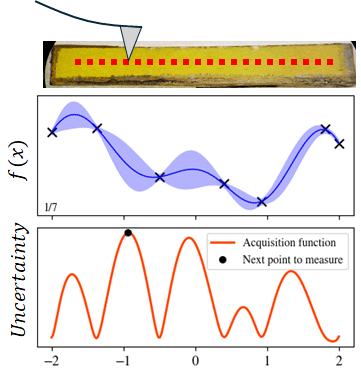

## Functions

In [1]:
!pip install gpytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.2/291.2 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8/174.8 kB 5.5 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import gpytorch

In [3]:
#@title target function

# F1 — Smooth unimodal
def unimodal(x):
    x = np.asarray(x)
    res = 0.15 * (x + 2)**2 + 0.03 * (x - 1)**4
    return res


# F2 — Double-well
def double_well(x):
    x = np.asarray(x)
    res = 0.08 * (x**2 - 4)**2 + 0.15 * x

    return res


# F3 — Multimodal (Rastrigin-like, 1D)
def multimodal(x):
    x = np.asarray(x)
    res = 10 + x**2 - 7 * np.cos(2 * np.pi * x) + 9 * np.sin(1.4 * np.pi * x)
    return res


# F4 — Broad + narrow minima
def broad_narrow(x):
    x = np.asarray(x)

    res = (
        1
        - 1.0 * np.exp(-((x + 1.5)**2) / (2 * 0.9**2))
        - 1.6 * np.exp(-((x - 1.0)**2) / (2 * 0.18**2))
    )
    return res

In [4]:
#@title simple noise models

def noise_constant(x = None, t = None, sigma0=0.1):
    t = np.asarray(t)
    return sigma0 * np.ones_like(t, dtype=float)

def noise_decay_floor(x = None, t = None, sigma_min=0.05, A=0.18, tau=1.0):
    t = np.asarray(t)
    return sigma_min + A * np.exp(-t / tau)

In [5]:
#@title heteroskedastic_noise_model

def make_heteroskedastic_noise_model(f, xlim, n_grid=200, smooth_window=3):
    """
    Build heteroskedastic noise model on a fixed domain.

    Parameters
    ----------
    f : callable
        Ground truth function
    xlim : tuple (xmin, xmax)
        Domain of interest
    """

    xmin, xmax = xlim
    x_grid = np.linspace(xmin, xmax, n_grid)
    y_grid = f(x_grid)

    # gradient
    grad = np.abs(np.gradient(y_grid, x_grid, edge_order=2))

    # smoothing
    if smooth_window > 1:
        kernel = np.ones(smooth_window) / smooth_window
        half = smooth_window // 2
        grad_s = np.pad(grad, pad_width=half, mode="reflect")
        grad = np.convolve(grad_s, kernel, mode="valid")

    # normalization
    scale = np.percentile(grad, 95) + 1e-12
    grad_norm_grid = grad / scale

    def noise_model(x, t, sigma_min=0.05, sigma_max=0.5, tau=1.5):
        x = np.asarray(x, dtype=float)
        t = np.asarray(t, dtype=float)

        g = np.interp(x, x_grid, grad_norm_grid)
        sigma0_x = sigma_min + (sigma_max - sigma_min) * g

        return sigma_min + (sigma0_x - sigma_min) * np.exp(-t / tau)

    return noise_model

In [6]:
#@title measurement simulator

class MeasurementSimulator:
    def __init__(self, ground_truth_model, noise_model, rng=None, **noise_kwargs):
        """
        Parameters
        ----------
        ground_truth_model : callable
            Function f(x)
        noise_model : callable
            Function sigma(x, t, **noise_kwargs)
        rng : None, int, or np.random.Generator
            Random generator or seed
        **noise_kwargs
            Default parameters for noise_model
        """
        self.f = ground_truth_model
        self.noise_model = noise_model
        self.noise_kwargs = noise_kwargs

        if rng is None:
            self.rng = np.random.default_rng()
        elif isinstance(rng, (int, np.integer)):
            self.rng = np.random.default_rng(rng)
        else:
            self.rng = rng

    def measure(self, coords, **noise_kwargs):
        """
        coords : array of shape (N, 2)
            Columns are (x, t)

        Returns
        -------
        y_meas : array of shape (N,)
            Noisy measurements
        """
        coords = np.asarray(coords, dtype=float)

        if coords.ndim != 2 or coords.shape[1] != 2:
            raise ValueError("coords must have shape (N, 2)")

        x = coords[:, 0]
        t = coords[:, 1]

        kwargs = {**self.noise_kwargs, **noise_kwargs}
        sigma = np.asarray(self.noise_model(x, t, **kwargs), dtype=float)
        noise = self.rng.normal(0.0, sigma, size=len(x))

        return self.f(x) + noise

    __call__ = measure

In [7]:
#@title gp functions

import torch
import gpytorch


def gp_predict(x_train, y_train, x_test, training_iter=100, lr=0.1):
    """
    Fit GP on (x_train, y_train) and predict on x_test.

    Parameters
    ----------
    x_train : array-like (N,)
    y_train : array-like (N,)
    x_test  : array-like (M,)

    Returns
    -------
    mean : (M,)
    std  : (M,)
    """

    # convert to torch
    x_train = torch.as_tensor(x_train, dtype=torch.float32)
    y_train = torch.as_tensor(y_train, dtype=torch.float32)
    x_test  = torch.as_tensor(x_test, dtype=torch.float32)

    # ensure 2D inputs
    if x_train.ndim == 1:
        x_train = x_train.unsqueeze(-1)
    if x_test.ndim == 1:
        x_test = x_test.unsqueeze(-1)

    # define model
    likelihood = gpytorch.likelihoods.GaussianLikelihood()

    class GPModel(gpytorch.models.ExactGP):
        def __init__(self, train_x, train_y, likelihood):
            super().__init__(train_x, train_y, likelihood)
            self.mean_module = gpytorch.means.ConstantMean()
            self.covar_module = gpytorch.kernels.ScaleKernel(
                gpytorch.kernels.RBFKernel()
            )

        def forward(self, x):
            mean = self.mean_module(x)
            covar = self.covar_module(x)
            return gpytorch.distributions.MultivariateNormal(mean, covar)

    model = GPModel(x_train, y_train, likelihood)

    # train
    model.train()
    likelihood.train()

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

    for _ in range(training_iter):
        optimizer.zero_grad()
        output = model(x_train)
        loss = -mll(output, y_train)
        loss.backward()
        optimizer.step()

    # predict
    model.eval()
    likelihood.eval()

    with torch.no_grad():
        pred = likelihood(model(x_test))
        mean = pred.mean.cpu().numpy()
        std = pred.stddev.cpu().numpy()

    return mean, std

In [8]:
#@title cost models

def travel_cost(dx, speed=0.5) -> float:
  return abs(dx) / speed


## Introduction

In [9]:
x = np.linspace(-4,4,100) #spatial coordinate (compositional/parameter space)
t = np.linspace(0,10,100) #acquisition time

We suggest selecting one of the following four “ground truth” functions to represent the underlying functionality.

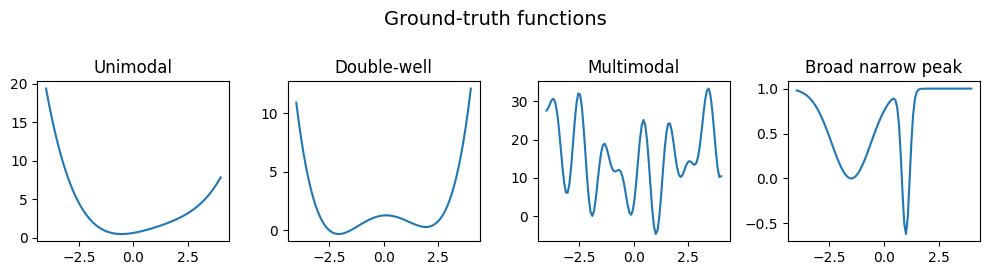

In [10]:
#ground truth functions
fig, ax = plt.subplots(1,4, figsize=(10, 2.7))

ax[0].plot(x, unimodal(x))
ax[1].plot(x, double_well(x))
ax[2].plot(x, multimodal(x))
ax[3].plot(x, broad_narrow(x))

ax[0].set_title('Unimodal')
ax[1].set_title('Double-well')
ax[2].set_title('Multimodal')
ax[3].set_title('Broad narrow peak')

fig.suptitle('Ground-truth functions', y=1, fontsize=14)

plt.tight_layout()

To emulate noisy measurements, we consider two homoscedastic noise models. The first is a **constant noise** model (trivial case), where the measurement precision is independent of acquisition time. The second is a **decaying noise** model, where the noise decreases exponentially with acquisition time and approaches a maximum achievable precision.

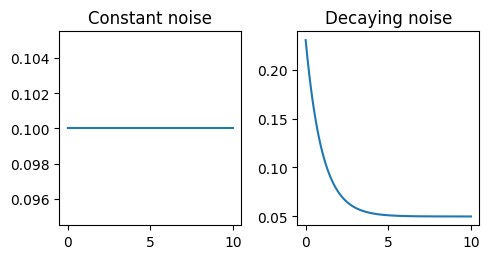

In [11]:
#homoskedastic noise model

fig, ax = plt.subplots(1,2, figsize=(5, 2.7))

ax[0].plot(t, noise_constant(x, t))
ax[0].set_title('Constant noise')
ax[1].plot(t, noise_decay_floor(x, t))
ax[1].set_title('Decaying noise')

plt.tight_layout()

For those seeking more hardcore challenge, we also suggest a **heteroscedastic noise model**, where the measurement noise depends on the location. In our specific case, the noise level is proportional to the local gradient of the underlying function, while still decaying with acquisition time toward a limiting precision.

Text(0.5, 0.98, 'Heteroskedastic noise model')

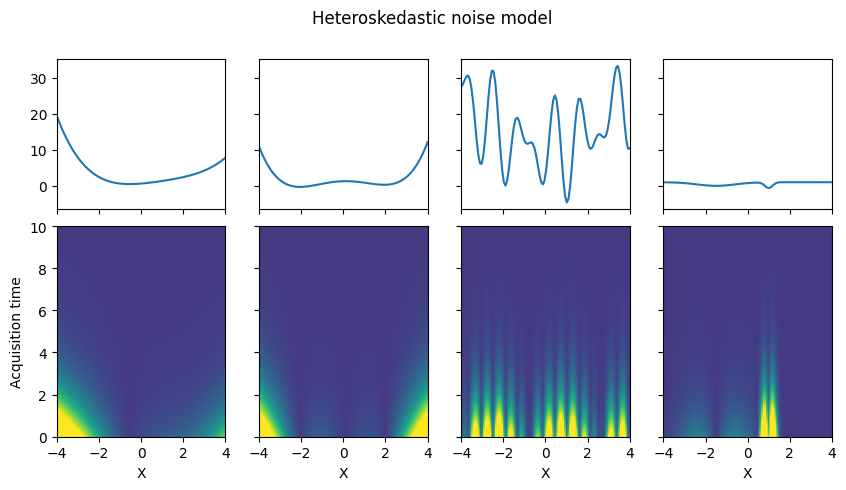

In [12]:
#@title heteroskedastic noise model

funcs = [unimodal, double_well, multimodal, broad_narrow]

fig, ax = plt.subplots(2, 4, figsize=(10, 5),
                       height_ratios=(1,1.5),
                       sharex=True,
                       sharey='row',
                       gridspec_kw={'hspace': 0.05})

for i,ax0_ in enumerate(ax[0]):
  ax0_.plot(x, funcs[i](x))

for i,ax1_ in enumerate(ax[1]):
  noise_model = make_heteroskedastic_noise_model(funcs[i], (-4, 4))
  ax1_.imshow(noise_model(x, t.reshape(-1,1)),
              origin='lower',
              extent=[x.min(), x.max(), t.min(), t.max()],
              vmax=.3, vmin=0)
  ax1_.set_xlabel('X')

ax[1,0].set_ylabel('Acquisition time')

fig.suptitle('Heteroskedastic noise model')


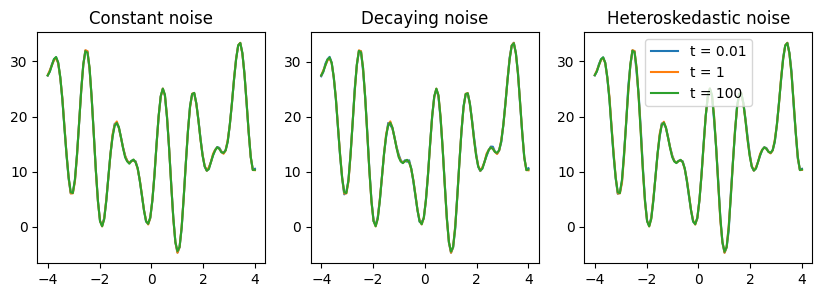

In [13]:
#@title example: grid measurements with different acqusition time

x = np.linspace(-4,4, 100) #x grid

durations = [0.01, 1, 100] #select durations
model = multimodal #select model [unimodal, double_well, multimodal, broad_narrow]

noise_heter_model = make_heteroskedastic_noise_model(model, (-4, 4))

sim_const = MeasurementSimulator(
    ground_truth_model=model,
    noise_model=noise_constant,
    rng=123,
)

sim_decay = MeasurementSimulator(
    ground_truth_model=model,
    noise_model=noise_decay_floor,
    rng=123,
)

sim_heterosk = MeasurementSimulator(
    ground_truth_model=model,
    noise_model=noise_heter_model,
    rng=123,
)

fig, ax = plt.subplots(1, 3, figsize=(10,3))

for d in durations:
  d_ar = np.ones(len(x))*d
  coords = np.vstack([x, d_ar]).T

  ax[0].plot(coords[:,0], sim_const.measure(coords), label = f't = {d}')
  ax[1].plot(coords[:,0], sim_decay.measure(coords), label = f't = {d}')
  ax[2].plot(coords[:,0], sim_heterosk.measure(coords), label = f't = {d}')

ax[0].set_title('Constant noise')
ax[1].set_title('Decaying noise')
ax[2].set_title('Heteroskedastic noise')
ax[2].legend()

In [14]:
#@title example: surrogate modeling

#homoskedatic noise model: [noise_constant, noise_decay_floor]
#ground truth models: [unimodal, double_well, multimodal, broad_narrow]


#If we select the heteroskedastic noise model, we first need to construct it. For the homoskedastic cases, the models are already defined.
noise_heter_model = make_heteroskedastic_noise_model(double_well, xlim=(-4, 4)) #please define the x range

meas_sim = MeasurementSimulator(
    ground_truth_model=double_well,
    noise_model=noise_heter_model,
    rng=123,
)

In [15]:

#define x_grid on the explored interval

x_grid = np.linspace(-4, 4, 500)

# For this example, select 4 random locations in the range (-4, 4)
x = np.random.random(7) * 8 - 4

# Set acquisition time (t = 3) for all locations
t = np.ones(len(x)) * 1

# Form the coordinate array: [[x1, t1], [x2, t2], ...]
coords = np.column_stack([x, t])

#make "measurements"
y = meas_sim.measure(coords)

#surrogate modeling
mean, std = gp_predict(x, y, x_grid, training_iter=100, lr=0.1)

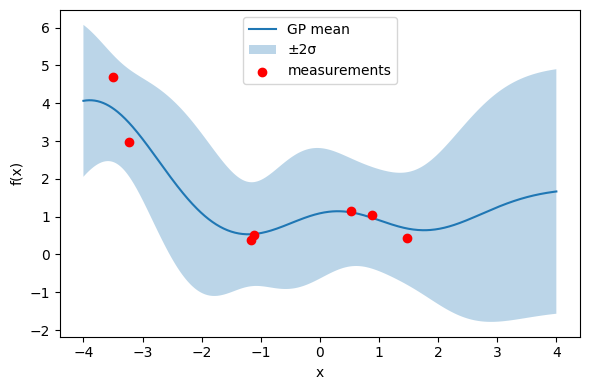

In [16]:
plt.figure(figsize=(6, 4))

# GP mean
plt.plot(x_grid, mean, label="GP mean")

# uncertainty band
plt.fill_between(
  x_grid,
  mean - 2 * std,
  mean + 2 * std,
  alpha=0.3,
  label="±2σ"
)

# training points
plt.scatter(x, y, color="red", zorder=3, label="measurements")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.tight_layout()
plt.show()

For simplicity, we treat time as the cost function. The cost of a single measurement is therefore equal to its acquisition time. In addition, we introduce a travel cost, which accounts for moving between measurement locations and is assumed to be proportional to the distance between them.

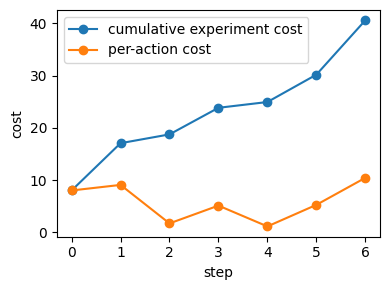

In [17]:
#@title total experiment cost

# initial position
x0 = 0

# displacement between consecutive points (including first move from x0)
dx = x - np.append(x0, x[:-1])

# cost of each action = travel cost + acquisition time
action_costs = travel_cost(dx) + t

# visualize costs
fig = plt.figure(figsize=(4,3))
plt.plot(np.cumsum(action_costs), 'o-', label='cumulative experiment cost')
plt.plot(action_costs, 'o-', label='per-action cost')

plt.xlabel('step')
plt.ylabel('cost')
plt.legend()
plt.tight_layout()




---


## Lets go!
---



Design a strategy that selects where to measure, in what order, and for how long, using the provided simulator and a fixed total budget. The objective is to explore or optimize the underlying function as efficiently as possible under noisy measurements and movement cost.

In [18]:
B = 100 #your budget

meas_sim = MeasurementSimulator(
    ground_truth_model=double_well, #choose gt function
    noise_model=noise_decay_floor,  #choose noise model
    rng=123,
)

In [ ]:
#your code

In [19]:
from dataclasses import dataclass, field
from typing import Callable, Sequence
import numpy as np


@dataclass
class MeasurementProblemDefinition:
    budget: float = 100.0
    x_domain: tuple[float, float] = (-4.0, 4.0)
    x_grid_size: int = 100
    t_choices: Sequence[float] = (0.000001,0.01, 1.0, 100.0, 10000)

    ground_truth_model: Callable = None
    noise_model: Callable = None
    rng_seed: int = 123

    move_speed: float = 1.0
    move_cost_weight: float = 1.0
    acquisition_cost_weight: float = 1.0

    def __post_init__(self):
        if self.ground_truth_model is None:
            raise ValueError("ground_truth_model must be provided")
        if self.noise_model is None:
            raise ValueError("noise_model must be provided")
        if self.budget <= 0:
            raise ValueError("budget must be positive")
        if self.x_grid_size < 2:
            raise ValueError("x_grid_size must be at least 2")
        if len(self.t_choices) == 0:
            raise ValueError("t_choices cannot be empty")

        self.x_grid = np.linspace(self.x_domain[0], self.x_domain[1], self.x_grid_size)

    @property
    def action_space(self):
        return [(x, t) for x in self.x_grid for t in self.t_choices]

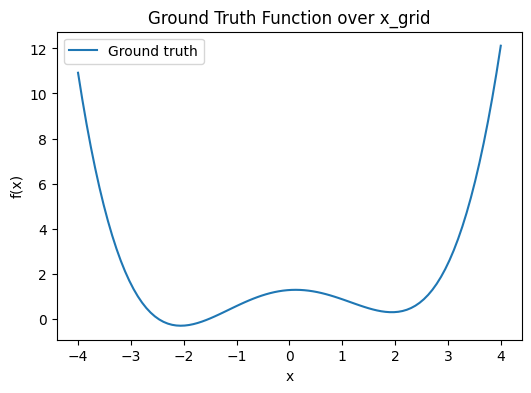

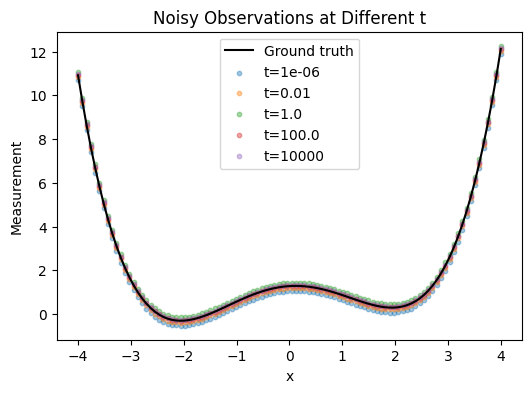

Action space size: 500
Example actions: [(np.float64(-4.0), 1e-06), (np.float64(-4.0), 0.01), (np.float64(-4.0), 1.0), (np.float64(-4.0), 100.0), (np.float64(-4.0), 10000)]


In [20]:
problem = MeasurementProblemDefinition(
    budget=100.0,
    ground_truth_model=double_well,
    noise_model=noise_decay_floor,
    rng_seed=123,
)
import matplotlib.pyplot as plt

x = problem.x_grid
y = problem.ground_truth_model(x)

plt.figure(figsize=(6,4))
plt.plot(x, y, label="Ground truth")
plt.title("Ground Truth Function over x_grid")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.show()

rng = np.random.default_rng(problem.rng_seed)

plt.figure(figsize=(6,4))
plt.plot(x, y, label="Ground truth", color="black")

for t in problem.t_choices:
    noise = problem.noise_model(x, t)
    y_noisy = y + rng.normal(0, noise)
    plt.scatter(x, y_noisy, s=10, alpha=0.4, label=f"t={t}")

plt.title("Noisy Observations at Different t")
plt.xlabel("x")
plt.ylabel("Measurement")
plt.legend()
plt.show()


print("Action space size:", len(problem.action_space))
print("Example actions:", problem.action_space[:5])

# Environment

In [21]:
import numpy as np


class MeasurementEnvironment:
    def __init__(self, params: MeasurementProblemDefinition):
        self.params = params

        self.simulator = MeasurementSimulator(
            ground_truth_model=params.ground_truth_model,
            noise_model=params.noise_model,
            rng=params.rng_seed,
        )

        self.reset()

    def reset(self, x_start=None):
        if x_start is None:
            x_start = float(self.params.x_grid[len(self.params.x_grid) // 2])

        self.step_count = 0
        self.x_current = float(x_start)
        self.budget_remaining = float(self.params.budget)

        self.X_obs = []
        self.Y_obs = []
        self.T_obs = []

        return self.get_state()

    def get_state(self):
        return {
            "step": self.step_count,
            "x_current": self.x_current,
            "budget_remaining": self.budget_remaining,
            "X_obs": np.array(self.X_obs, dtype=float),
            "Y_obs": np.array(self.Y_obs, dtype=float),
            "T_obs": np.array(self.T_obs, dtype=float),
        }

    def movement_cost(self, x_from, x_to):
        distance = abs(float(x_to) - float(x_from))
        return self.params.move_cost_weight * (distance / self.params.move_speed)

    def acquisition_cost(self, t):
        return self.params.acquisition_cost_weight * float(t)

    def total_cost(self, x_next, t_next):
        return self.movement_cost(self.x_current, x_next) + self.acquisition_cost(t_next)

    def is_feasible(self, x_next, t_next):
        return self.total_cost(x_next, t_next) <= self.budget_remaining

    def step(self, action):
        x_next, t_next = action
        x_next = float(x_next)
        t_next = float(t_next)

        x_prev = self.x_current
        movement_cost = self.movement_cost(x_prev, x_next)
        acquisition_cost = self.acquisition_cost(t_next)
        cost = movement_cost + acquisition_cost

        if cost > self.budget_remaining:
            raise ValueError(
                f"Infeasible action: cost={cost:.4f} exceeds remaining budget={self.budget_remaining:.4f}"
            )

        coords = np.array([[x_next, t_next]], dtype=float)
        y_next = float(self.simulator.measure(coords)[0])

        self.X_obs.append(x_next)
        self.Y_obs.append(y_next)
        self.T_obs.append(t_next)

        self.x_current = x_next
        self.budget_remaining -= cost
        self.step_count += 1

        done = self.budget_remaining <= 0.0

        info = {
            "measurement": y_next,
            "x_prev": x_prev,
            "x_next": x_next,
            "t_next": t_next,
            "cost": cost,
            "movement_cost": movement_cost,
            "acquisition_cost": acquisition_cost,
        }

        return self.get_state(), done, info

# Reward

In [22]:
from dataclasses import dataclass
from typing import Callable, Optional
import numpy as np


@dataclass
class RewardFunctions:
    """
    Reward functions are kept separate from the environment.
    They use the original environment/state/cost definitions as-is.
    """

    @staticmethod
    def exploration_proxy(gp_std_at_x: float) -> float:
        """
        Reward 1:
        Simple exploration reward = GP uncertainty at chosen point.
        """
        return float(gp_std_at_x)

    @staticmethod
    def noise_aware_information(gp_std_at_x: float, noise_std_at_x_t: float, eps: float = 1e-12) -> float:
        """
        Reward 2:
        Prefer high GP uncertainty and low measurement noise.
        """
        return float((gp_std_at_x ** 2) / (noise_std_at_x_t ** 2 + eps))

    @staticmethod
    def cost_aware_information(
        info_gain: float,
        action_cost: float,
        eps: float = 1e-12
    ) -> float:
        """
        Reward 3:
        Information per unit cost.
        """
        return float(info_gain / (action_cost + eps))

    @staticmethod
    def improvement_in_best(
        y_next: float,
        y_best_prev: Optional[float]
    ) -> float:
        """
        Reward 4:
        Improvement over best observed value so far.
        """
        if y_best_prev is None:
            return 0.0
        return float(max(0.0, y_next - y_best_prev))

    @staticmethod
    def global_variance_reduction(
        old_std: np.ndarray,
        new_std: np.ndarray
    ) -> float:
        """
        Reward 5:
        Total reduction in GP uncertainty over the full domain.
        """
        old_std = np.asarray(old_std, dtype=float)
        new_std = np.asarray(new_std, dtype=float)
        return float(np.sum(old_std**2 - new_std**2))

# Single Bandit Check

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import gpytorch


# =========================================================
# GP HELPER: exact GP + Matern kernel, x-only
# =========================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class ExactMaternGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)

        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(nu=1.5)
        )

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)


class GPHelper:
    def __init__(self, lr=0.1, iters=300):
        self.lr = lr
        self.iters = iters

        self.model = None
        self.likelihood = None

        self.x_mu = 0.0
        self.x_sigma = 1.0
        self.y_mu = 0.0
        self.y_sigma = 1.0
        self.train_y_mean = 0.0

    @staticmethod
    def _safe_numpy_1d(x):
        return np.asarray(x, dtype=float).reshape(-1)

    def fit(self, x_train, y_train):
        x_train = self._safe_numpy_1d(x_train)
        y_train = self._safe_numpy_1d(y_train)

        if len(x_train) < 2:
            self.model = None
            self.likelihood = None
            self.train_y_mean = float(np.mean(y_train)) if len(y_train) > 0 else 0.0
            return

        self.x_mu = float(np.mean(x_train))
        self.x_sigma = float(np.std(x_train))
        if self.x_sigma < 1e-6:
            self.x_sigma = 1.0

        self.y_mu = float(np.mean(y_train))
        self.y_sigma = float(np.std(y_train))
        if self.y_sigma < 1e-6:
            self.y_sigma = 1.0

        x_train_norm = (x_train - self.x_mu) / self.x_sigma
        y_train_norm = (y_train - self.y_mu) / self.y_sigma

        train_x = torch.tensor(x_train_norm, dtype=torch.float32, device=device)
        train_y = torch.tensor(y_train_norm, dtype=torch.float32, device=device)

        likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device)
        model = ExactMaternGPModel(train_x, train_y, likelihood).to(device)

        model.train()
        likelihood.train()

        optimizer = torch.optim.Adam(model.parameters(), lr=self.lr)
        mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

        for _ in range(self.iters):
            optimizer.zero_grad()
            output = model(train_x)
            loss = -mll(output, train_y)
            loss.backward()
            optimizer.step()

        self.model = model
        self.likelihood = likelihood
        self.train_y_mean = float(np.mean(y_train))

    def predict(self, x_test):
        x_test = self._safe_numpy_1d(x_test)

        if self.model is None or self.likelihood is None:
            mean = np.full(len(x_test), self.train_y_mean, dtype=float)
            std = np.full(len(x_test), 1.0, dtype=float)
            noise_std = np.full(len(x_test), 1.0, dtype=float)
            return mean, std, noise_std

        x_test_norm = (x_test - self.x_mu) / self.x_sigma
        test_x = torch.tensor(x_test_norm, dtype=torch.float32, device=device)

        self.model.eval()
        self.likelihood.eval()

        with torch.no_grad(), gpytorch.settings.fast_pred_var():
            latent_pred = self.model(test_x)

            mean = latent_pred.mean.detach().cpu().numpy()
            std = latent_pred.stddev.detach().cpu().numpy()

            noise_var = self.likelihood.noise.detach().cpu().numpy()
            noise_std = np.full(len(x_test), float(np.sqrt(noise_var)))

        mean = mean * self.y_sigma + self.y_mu
        std = std * self.y_sigma
        noise_std = noise_std * self.y_sigma

        return mean, std, noise_std



seed | x=-4.000 | t=1.000 | y=10.805 | cost=5.000 | budget=35.000
seed | x=-3.579 | t=1.000 | y=5.628 | cost=1.421 | budget=33.579
seed | x=-3.158 | t=1.000 | y=2.529 | cost=1.421 | budget=32.158
seed | x=-2.737 | t=1.000 | y=0.587 | cost=1.421 | budget=30.737
seed | x=-2.316 | t=1.000 | y=-0.092 | cost=1.421 | budget=29.316
seed | x=-1.895 | t=1.000 | y=-0.204 | cost=1.421 | budget=27.895
seed | x=-1.474 | t=1.000 | y=-0.028 | cost=1.421 | budget=26.474
seed | x=-1.053 | t=1.000 | y=0.574 | cost=1.421 | budget=25.053
seed | x=-0.632 | t=1.000 | y=0.906 | cost=1.421 | budget=23.632
seed | x=-0.211 | t=1.000 | y=1.183 | cost=1.421 | budget=22.211
seed | x=0.211 | t=1.000 | y=1.295 | cost=1.421 | budget=20.789
seed | x=0.632 | t=1.000 | y=0.955 | cost=1.421 | budget=19.368
seed | x=1.053 | t=1.000 | y=0.966 | cost=1.421 | budget=17.947
seed | x=1.474 | t=1.000 | y=0.410 | cost=1.421 | budget=16.526
seed | x=1.895 | t=1.000 | y=0.414 | cost=1.421 | budget=15.105
seed | x=2.316 | t=1.000 |

/tmp/ipykernel_13984/935071317.py:114: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  noise_std = np.full(len(x_test), float(np.sqrt(noise_var)))


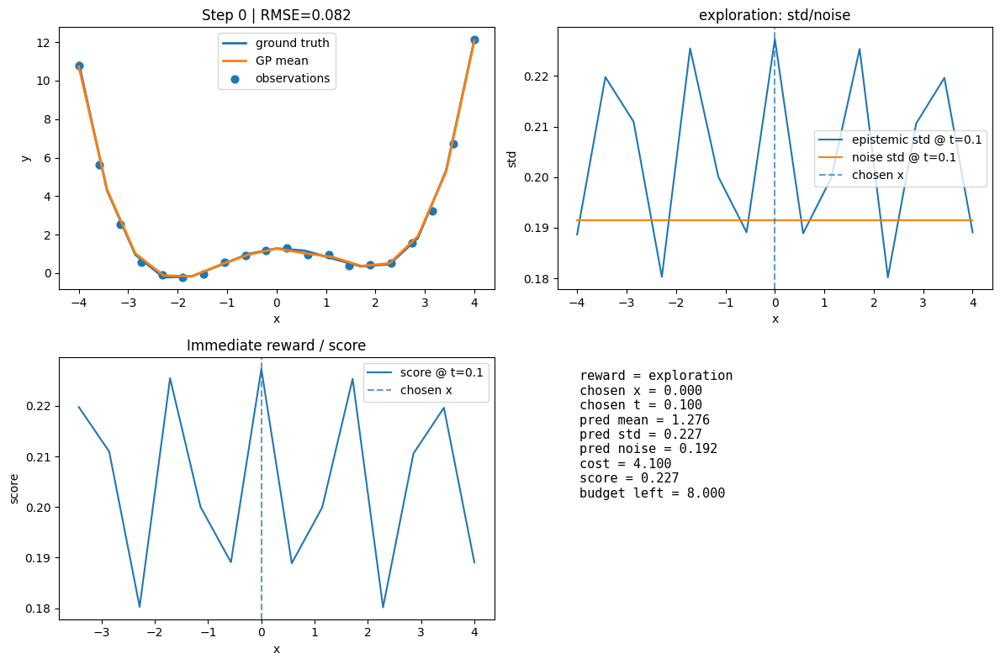

step=00 | x=0.000 | t=0.100 | y=0.810 | cost=4.100 | budget=3.900


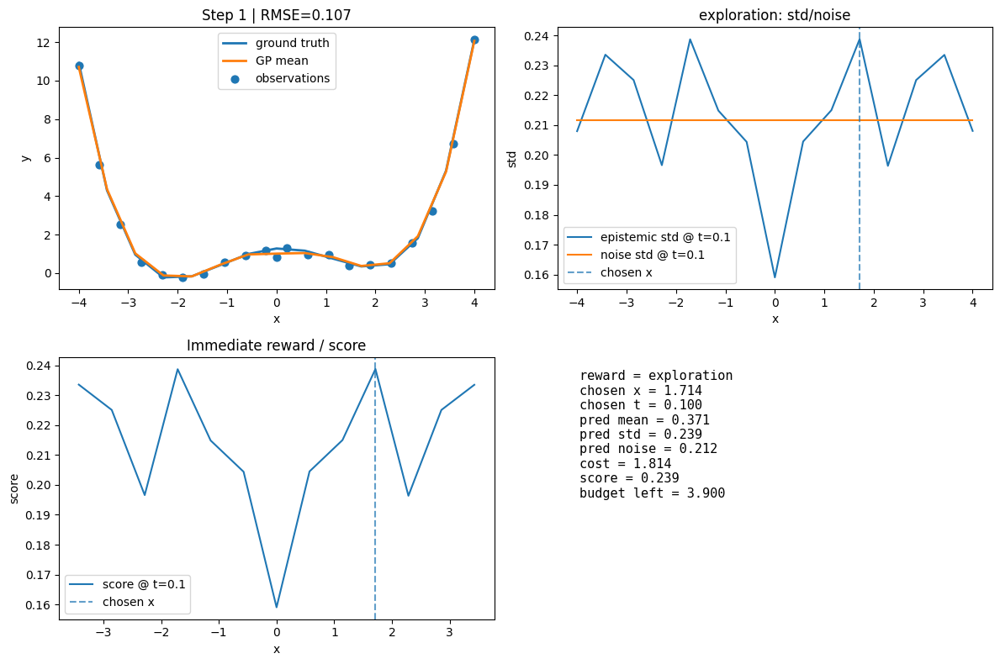

step=01 | x=1.714 | t=0.100 | y=0.523 | cost=1.814 | budget=2.086


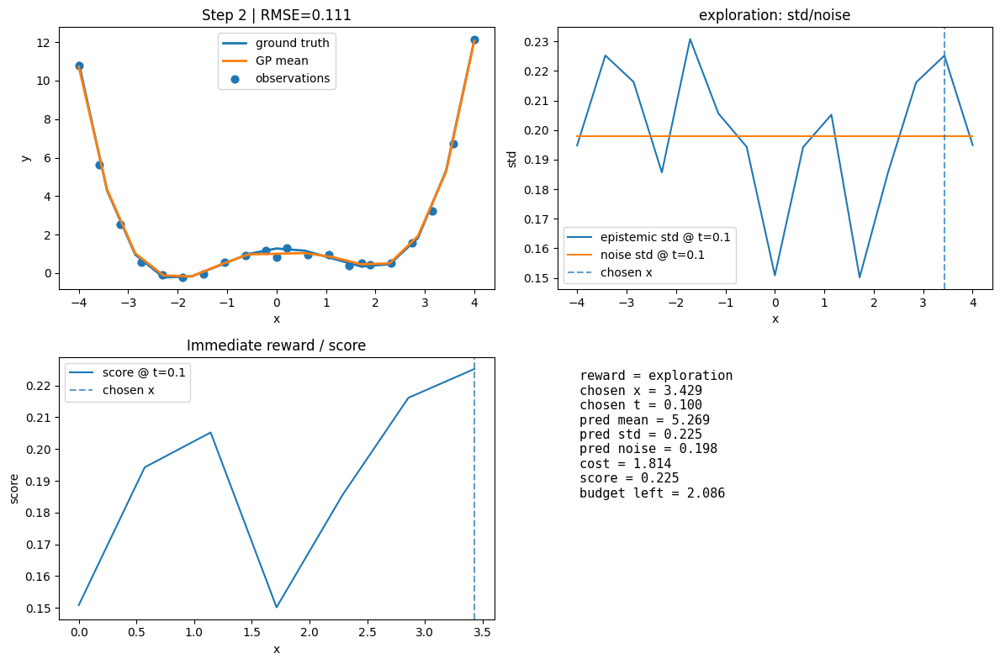

step=02 | x=3.429 | t=0.100 | y=5.654 | cost=1.814 | budget=0.271


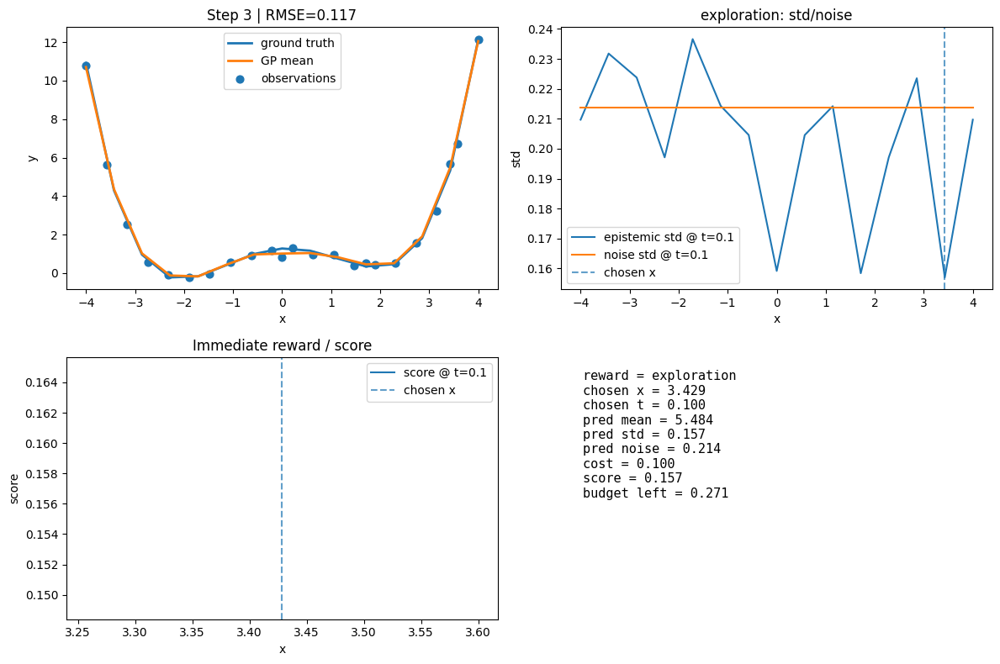

step=03 | x=3.429 | t=0.100 | y=5.565 | cost=0.100 | budget=0.171


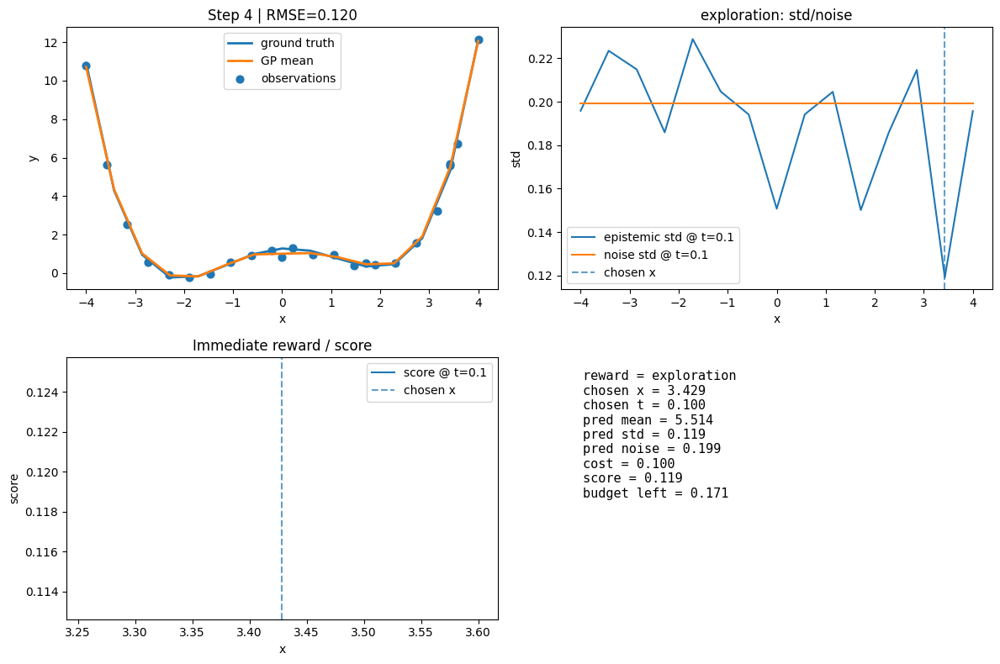

step=04 | x=3.429 | t=0.100 | y=5.486 | cost=0.100 | budget=0.071
Stopping early at step 5: No feasible action found


In [23]:

# =========================================================
# BANDIT HELPERS
# =========================================================
def bandit_score(reward_name, reward_fn, state, mean_val, std_val, noise_val, cost):
    if reward_name == "exploration":
        return reward_fn.exploration_proxy(std_val)

    elif reward_name == "noise_aware":
        return reward_fn.noise_aware_information(
            gp_std_at_x=std_val,
            noise_std_at_x_t=noise_val
        )

    elif reward_name == "cost_aware":
        info = reward_fn.noise_aware_information(
            gp_std_at_x=std_val,
            noise_std_at_x_t=noise_val
        )
        return reward_fn.cost_aware_information(
            info_gain=info,
            action_cost=cost
        )

    elif reward_name == "improvement":
        y_best_prev = np.max(state["Y_obs"]) if len(state["Y_obs"]) > 0 else None
        return reward_fn.improvement_in_best(
            y_next=mean_val,
            y_best_prev=y_best_prev
        )

    else:
        raise ValueError(f"Unknown reward_name: {reward_name}")


def precompute_gp_maps(state, problem, gp_helper):
    x_grid = problem.x_grid

    means, stds, noises = {}, {}, {}

    for t in problem.t_choices:
        mean, std, noise_std = gp_helper.predict(x_test=x_grid)
        means[t] = mean
        stds[t] = std
        noises[t] = noise_std

    return means, stds, noises


def precompute_bandit_maps(env, problem, gp_helper):
    state = env.get_state()

    x_train = state["X_obs"]
    y_train = state["Y_obs"]

    gp_helper.fit(x_train, y_train)

    means, stds, noises = precompute_gp_maps(state, problem, gp_helper)
    return means, stds, noises


def select_bandit_action(env, problem, gp_helper, reward_name="exploration"):
    reward_fn = RewardFunctions()
    state = env.get_state()

    means, stds, noises = precompute_bandit_maps(env, problem, gp_helper)

    best_score = -np.inf
    best_action = None
    best_info = None

    for i, x in enumerate(problem.x_grid):
        for t in problem.t_choices:
            if not env.is_feasible(x, t):
                continue

            cost = env.total_cost(x, t)

            mean_val = float(means[t][i])
            std_val = float(stds[t][i])
            noise_val = float(noises[t][i])

            score = bandit_score(
                reward_name=reward_name,
                reward_fn=reward_fn,
                state=state,
                mean_val=mean_val,
                std_val=std_val,
                noise_val=noise_val,
                cost=cost
            )

            if score > best_score:
                best_score = score
                best_action = (float(x), float(t))
                best_info = {
                    "x": float(x),
                    "t": float(t),
                    "mean": mean_val,
                    "std": std_val,
                    "noise": noise_val,
                    "cost": cost,
                    "score": score,
                }

    if best_action is None:
        raise ValueError("No feasible action found")

    return best_action, best_info, means, stds, noises


def evaluate_gp_for_plot(env, problem, gp_helper):
    state = env.get_state()
    x_train = state["X_obs"]
    y_train = state["Y_obs"]

    x_grid = problem.x_grid
    y_true = problem.ground_truth_model(x_grid)

    if len(x_train) < 2:
        mean = np.full_like(x_grid, np.mean(y_train) if len(y_train) > 0 else 0.0, dtype=float)
        std = np.ones_like(x_grid, dtype=float)
        rmse = np.sqrt(np.mean((mean - y_true) ** 2))
        return mean, std, rmse

    gp_helper.fit(x_train, y_train)
    mean, std, noise_std = gp_helper.predict(x_test=x_grid)

    rmse = np.sqrt(np.mean((mean - y_true) ** 2))
    return mean, std, rmse


def plot_bandit_step(env, problem, gp_helper, reward_name, step_idx, selected_info, means, stds, noises):
    state = env.get_state()
    x_grid = problem.x_grid
    y_true = problem.ground_truth_model(x_grid)

    mean_plot, std_plot, rmse = evaluate_gp_for_plot(env, problem, gp_helper)

    t_show = float(selected_info["t"])
    mean_show = means[t_show]
    std_show = stds[t_show]
    noise_show = noises[t_show]

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # top-left: GP mean vs truth
    ax = axes[0, 0]
    ax.plot(x_grid, y_true, label="ground truth", linewidth=2)
    ax.plot(x_grid, mean_plot, label="GP mean", linewidth=2)
    if len(state["X_obs"]) > 0:
        ax.scatter(state["X_obs"], state["Y_obs"], s=40, label="observations")
    ax.set_title(f"Step {step_idx} | RMSE={rmse:.3f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

    # top-right: uncertainty for selected t
    ax = axes[0, 1]
    ax.plot(x_grid, std_show, label=f"epistemic std @ t={t_show}")
    ax.plot(x_grid, noise_show, label=f"noise std @ t={t_show}")
    ax.axvline(selected_info["x"], linestyle="--", alpha=0.7, label="chosen x")
    ax.set_title(f"{reward_name}: std/noise")
    ax.set_xlabel("x")
    ax.set_ylabel("std")
    ax.legend()

    # bottom-left: reward landscape at selected t
    ax = axes[1, 0]
    reward_fn = RewardFunctions()
    scores = []
    for i, x in enumerate(x_grid):
        cost = env.total_cost(x, t_show)
        if env.is_feasible(x, t_show):
            s = bandit_score(
                reward_name=reward_name,
                reward_fn=reward_fn,
                state=state,
                mean_val=float(mean_show[i]),
                std_val=float(std_show[i]),
                noise_val=float(noise_show[i]),
                cost=cost
            )
        else:
            s = np.nan
        scores.append(s)

    ax.plot(x_grid, scores, label=f"score @ t={t_show}")
    ax.axvline(selected_info["x"], linestyle="--", alpha=0.7, label="chosen x")
    ax.set_title("Immediate reward / score")
    ax.set_xlabel("x")
    ax.set_ylabel("score")
    ax.legend()

    # bottom-right: text summary
    ax = axes[1, 1]
    ax.axis("off")
    txt = (
        f"reward = {reward_name}\n"
        f"chosen x = {selected_info['x']:.3f}\n"
        f"chosen t = {selected_info['t']:.3f}\n"
        f"pred mean = {selected_info['mean']:.3f}\n"
        f"pred std = {selected_info['std']:.3f}\n"
        f"pred noise = {selected_info['noise']:.3f}\n"
        f"cost = {selected_info['cost']:.3f}\n"
        f"score = {selected_info['score']:.3f}\n"
        f"budget left = {state['budget_remaining']:.3f}\n"
    )
    ax.text(0.05, 0.95, txt, va="top", family="monospace", fontsize=11)

    plt.tight_layout()
    plt.show()


def run_bandit_debug(
    problem,
    reward_name="exploration",
    x_start=0.0,
    t_init=1.0,
    n_steps=10,
    n_seed_points=3,
    gp_lr=0.05,
    gp_iters=150,
    verbose=True,
    plot_each_step=True,
):
    env = MeasurementEnvironment(problem)
    gp_helper = GPHelper(
        lr=gp_lr,
        iters=gp_iters
    )

    state = env.reset(x_start=x_start)

    x_min, x_max = problem.x_domain
    seed_xs = np.linspace(x_min, x_max, n_seed_points)

    for x_seed in seed_xs:
        x_seed = float(x_seed)
        if env.is_feasible(x_seed, t_init):
            state, done, info = env.step((x_seed, t_init))
            if verbose:
                print(
                    f"seed | x={x_seed:.3f} | "
                    f"t={t_init:.3f} | "
                    f"y={info['measurement']:.3f} | "
                    f"cost={info['cost']:.3f} | "
                    f"budget={state['budget_remaining']:.3f}"
                )
        else:
            raise ValueError(f"Seed point infeasible: x={x_seed:.3f}, t={t_init:.3f}")

    history = []

    for step_idx in range(n_steps):
        try:
            action, selected_info, means, stds, noises = select_bandit_action(
                env=env,
                problem=problem,
                gp_helper=gp_helper,
                reward_name=reward_name
            )
        except ValueError as e:
            print(f"Stopping early at step {step_idx}: {e}")
            break

        if plot_each_step:
            plot_bandit_step(
                env=env,
                problem=problem,
                gp_helper=gp_helper,
                reward_name=reward_name,
                step_idx=step_idx,
                selected_info=selected_info,
                means=means,
                stds=stds,
                noises=noises
            )

        next_state, done, info = env.step(action)

        history.append({
            "step": step_idx,
            "action": action,
            "measurement": info["measurement"],
            "cost": info["cost"],
            "budget_remaining": next_state["budget_remaining"],
            "selected_info": selected_info
        })

        if verbose:
            print(
                f"step={step_idx:02d} | "
                f"x={action[0]:.3f} | "
                f"t={action[1]:.3f} | "
                f"y={info['measurement']:.3f} | "
                f"cost={info['cost']:.3f} | "
                f"budget={next_state['budget_remaining']:.3f}"
            )

        if done:
            break

    return env, history


# =========================================================
# EXAMPLE RUN
# =========================================================
problem_small = MeasurementProblemDefinition(
    budget=40.0,
    ground_truth_model=double_well,
    noise_model=noise_decay_floor,
    rng_seed=123,
    x_domain=(-4.0, 4.0),
    x_grid_size=15,
    t_choices=(0.1, 1.0, 3.0),
)

env_dbg, hist_dbg = run_bandit_debug(
    problem=problem_small,
    reward_name="exploration",
    t_init=1.0,
    n_steps=12,
    n_seed_points=20,
    gp_lr=0.05,
    gp_iters=150,
    verbose=True,
    plot_each_step=True,
)

# Simulations seutp

In [32]:
# ---------------------------------------------------------
# FEATURES + Q MODEL
# ---------------------------------------------------------
def featurize(state, x, t, gp_mean, gp_std, noise_std, cost):
    return np.array([
        x,
        t,
        state["x_current"],
        state["budget_remaining"],
        gp_mean,
        gp_std,
        noise_std,
        cost
    ], dtype=float)


class LinearQ:
    def __init__(self, dim=8, lr=0.01):
        self.w = torch.zeros(dim, dtype=torch.float32, device=device)
        self.lr = lr

    def predict(self, phi):
        phi_t = torch.tensor(phi, dtype=torch.float32, device=device)
        return float(torch.dot(self.w, phi_t).item())

    def update(self, phi, target):
        phi_t = torch.tensor(phi, dtype=torch.float32, device=device)
        target_t = torch.tensor(float(target), dtype=torch.float32, device=device)
        pred = torch.dot(self.w, phi_t)
        self.w += self.lr * (target_t - pred) * phi_t




In [33]:

# ---------------------------------------------------------
# REWARD SELECTION
# ---------------------------------------------------------
def compute_reward(
    reward_name,
    reward_fn,
    y_next=None,
    y_best_prev=None,
    gp_std=None,
    noise_std=None,
    action_cost=None,
    old_std=None,
    new_std=None,
):
    if reward_name == "exploration":
        return reward_fn.exploration_proxy(gp_std)

    elif reward_name == "noise_aware":
        return reward_fn.noise_aware_information(
            gp_std_at_x=gp_std,
            noise_std_at_x_t=noise_std
        )

    elif reward_name == "cost_aware":
        info = reward_fn.noise_aware_information(
            gp_std_at_x=gp_std,
            noise_std_at_x_t=noise_std
        )
        return reward_fn.cost_aware_information(
            info_gain=info,
            action_cost=action_cost
        )

    elif reward_name == "improvement":
        return reward_fn.improvement_in_best(
            y_next=y_next,
            y_best_prev=y_best_prev
        )

    elif reward_name == "global_variance_reduction":
        if old_std is None or new_std is None:
            raise ValueError("old_std and new_std are required")
        return reward_fn.global_variance_reduction(old_std=old_std, new_std=new_std)

    else:
        raise ValueError(f"Unknown reward_name: {reward_name}")





In [34]:

# ---------------------------------------------------------
# GP RMSE
# ---------------------------------------------------------
def evaluate_current_gp_rmse(env, problem, gp_helper):
    state = env.get_state()

    x_train = state["X_obs"]
    y_train = state["Y_obs"]
    x_test = problem.x_grid
    y_true = problem.ground_truth_model(x_test)

    if len(x_train) < 2:
        mean = np.full_like(x_test, np.mean(y_train) if len(y_train) > 0 else 0.0, dtype=float)
        rmse = np.sqrt(np.mean((mean - y_true) ** 2))
        avg_std = 1.0
        return {
            "mean": mean,
            "rmse": float(rmse),
            "avg_std": float(avg_std),
        }

    gp_helper.fit(x_train, y_train)
    mean, std, noise_std = gp_helper.predict(x_test=x_test)

    rmse = np.sqrt(np.mean((mean - y_true) ** 2))
    avg_std = float(np.mean(std))

    return {
        "mean": mean,
        "rmse": float(rmse),
        "avg_std": avg_std,
    }


# ---------------------------------------------------------
# GP PRECOMPUTE HELPERS
# ---------------------------------------------------------
def precompute_gp_maps(state, problem, gp_helper):
    x_train = state["X_obs"]
    y_train = state["Y_obs"]

    means, stds, noises = {}, {}, {}
    x_grid = problem.x_grid

    if len(x_train) == 0:
        for t in problem.t_choices:
            means[t] = np.zeros_like(x_grid, dtype=float)
            stds[t] = np.ones_like(x_grid, dtype=float)
            noises[t] = np.ones_like(x_grid, dtype=float)
        return means, stds, noises

    gp_helper.fit(x_train, y_train)
    mean, std, noise_std = gp_helper.predict(x_test=x_grid)

    for t in problem.t_choices:
        means[t] = mean.copy()
        stds[t] = std.copy()
        noises[t] = noise_std.copy()

    return means, stds, noises


def max_q_over_feasible_actions(state, env, problem, q_model, gp_helper):
    means, stds, noises = precompute_gp_maps(state, problem, gp_helper)
    best_q = -np.inf

    for i, x in enumerate(problem.x_grid):
        for t in problem.t_choices:
            if not env.is_feasible(x, t):
                continue

            cost = env.total_cost(x, t)
            phi = featurize(
                state, x, t,
                gp_mean=float(means[t][i]),
                gp_std=float(stds[t][i]),
                noise_std=float(noises[t][i]),
                cost=cost
            )
            q_val = q_model.predict(phi)
            best_q = max(best_q, q_val)

    return 0.0 if best_q == -np.inf else best_q


def compute_backup_target(rewards, future_q, gamma, depth):
    if depth < 0:
        raise ValueError("depth must be >= 0")

    discounted_reward_sum = 0.0
    for k, r in enumerate(rewards):
        discounted_reward_sum += (gamma ** k) * r

    if depth == 0:
        return rewards[0]

    return discounted_reward_sum + (gamma ** len(rewards)) * future_q

In [35]:

# ---------------------------------------------------------
# POLICIES
# ---------------------------------------------------------
class RandomMeasurementPolicy:
    def select_action(self, env, problem):
        feasible_actions = [
            (float(x), float(t))
            for x in problem.x_grid
            for t in problem.t_choices
            if env.is_feasible(x, t)
        ]
        if len(feasible_actions) == 0:
            raise ValueError("No feasible action found")
        action = feasible_actions[np.random.randint(len(feasible_actions))]
        return action, None


class BanditPolicy:
    def __init__(self, gp_helper, reward_fn, reward_name="cost_aware", epsilon=0.1):
        self.gp_helper = gp_helper
        self.reward_fn = reward_fn
        self.reward_name = reward_name
        self.epsilon = epsilon

    def _compute_score(
        self,
        state,
        mean_val,
        std_val,
        noise_val,
        cost,
        old_std_grid=None,
        new_std_grid=None,
    ):
        if self.reward_name == "exploration":
            return self.reward_fn.exploration_proxy(std_val)

        elif self.reward_name == "noise_aware":
            return self.reward_fn.noise_aware_information(
                gp_std_at_x=std_val,
                noise_std_at_x_t=noise_val
            )

        elif self.reward_name == "cost_aware":
            info = self.reward_fn.noise_aware_information(
                gp_std_at_x=std_val,
                noise_std_at_x_t=noise_val
            )
            return self.reward_fn.cost_aware_information(
                info_gain=info,
                action_cost=cost
            )

        elif self.reward_name == "improvement":
            y_best_prev = np.max(state["Y_obs"]) if len(state["Y_obs"]) > 0 else None
            return self.reward_fn.improvement_in_best(
                y_next=mean_val,
                y_best_prev=y_best_prev
            )

        elif self.reward_name == "global_variance_reduction":
            if old_std_grid is None or new_std_grid is None:
                raise ValueError("global_variance_reduction requires old_std_grid and new_std_grid")
            return self.reward_fn.global_variance_reduction(
                old_std=old_std_grid,
                new_std=new_std_grid
            )

        else:
            raise ValueError(f"Unknown reward_name: {self.reward_name}")

    def select_action(self, env, problem):
        state = env.get_state()
        x_train = state["X_obs"]
        y_train = state["Y_obs"]

        if len(x_train) == 0:
            x0 = float(problem.x_grid[0])
            t0 = float(problem.t_choices[0])
            cost0 = env.total_cost(x0, t0)

            phi = featurize(
                state, x0, t0,
                gp_mean=0.0,
                gp_std=1.0,
                noise_std=1.0,
                cost=cost0
            )
            return (x0, t0), phi

        means, stds, noises = precompute_gp_maps(state, problem, self.gp_helper)

        feasible_actions = [
            (float(x), float(t))
            for x in problem.x_grid
            for t in problem.t_choices
            if env.is_feasible(x, t)
        ]
        if len(feasible_actions) == 0:
            raise ValueError("No feasible action found")

        if np.random.rand() < self.epsilon:
            x_rand, t_rand = feasible_actions[np.random.randint(len(feasible_actions))]
            i = np.where(np.isclose(problem.x_grid, x_rand))[0][0]

            phi = featurize(
                state, x_rand, t_rand,
                gp_mean=float(means[t_rand][i]),
                gp_std=float(stds[t_rand][i]),
                noise_std=float(noises[t_rand][i]),
                cost=env.total_cost(x_rand, t_rand)
            )
            return (x_rand, t_rand), phi

        best_score = -np.inf
        best_action = None
        best_phi = None

        old_std_grid_cache = {}
        if self.reward_name == "global_variance_reduction":
            for t in problem.t_choices:
                old_std_grid_cache[t] = stds[t].copy()

        for i, x in enumerate(problem.x_grid):
            for t in problem.t_choices:
                if not env.is_feasible(x, t):
                    continue

                cost = env.total_cost(x, t)
                mean_val = float(means[t][i])
                std_val = float(stds[t][i])
                noise_val = float(noises[t][i])

                old_std_grid = None
                new_std_grid = None

                if self.reward_name == "global_variance_reduction":
                    x_aug = np.append(x_train, x)
                    y_aug = np.append(y_train, mean_val)

                    temp_gp = GPHelper(lr=self.gp_helper.lr, iters=self.gp_helper.iters)
                    temp_gp.fit(x_aug, y_aug)
                    _, new_std_grid, _ = temp_gp.predict(problem.x_grid)

                    old_std_grid = old_std_grid_cache[t]

                score = self._compute_score(
                    state=state,
                    mean_val=mean_val,
                    std_val=std_val,
                    noise_val=noise_val,
                    cost=cost,
                    old_std_grid=old_std_grid,
                    new_std_grid=new_std_grid,
                )

                phi = featurize(
                    state, x, t,
                    gp_mean=mean_val,
                    gp_std=std_val,
                    noise_std=noise_val,
                    cost=cost
                )

                if score > best_score:
                    best_score = score
                    best_action = (float(x), float(t))
                    best_phi = phi

        if best_action is None:
            raise ValueError("No feasible action found")

        return best_action, best_phi


class RLPolicy:
    def __init__(self, gp_helper, q_model, epsilon=0.1):
        self.gp_helper = gp_helper
        self.q_model = q_model
        self.epsilon = epsilon

    def select_action(self, env, problem):
        state = env.get_state()
        means, stds, noises = precompute_gp_maps(state, problem, self.gp_helper)

        feasible_actions = [
            (float(x), float(t))
            for x in problem.x_grid
            for t in problem.t_choices
            if env.is_feasible(x, t)
        ]

        if len(feasible_actions) == 0:
            raise ValueError("No feasible action found")

        if np.random.rand() < self.epsilon:
            x_rand, t_rand = feasible_actions[np.random.randint(len(feasible_actions))]
            i = np.where(np.isclose(problem.x_grid, x_rand))[0][0]

            phi = featurize(
                state, x_rand, t_rand,
                gp_mean=float(means[t_rand][i]),
                gp_std=float(stds[t_rand][i]),
                noise_std=float(noises[t_rand][i]),
                cost=env.total_cost(x_rand, t_rand)
            )
            return (x_rand, t_rand), phi

        best_q = -np.inf
        best_action = None
        best_phi = None

        for i, x in enumerate(problem.x_grid):
            for t in problem.t_choices:
                if not env.is_feasible(x, t):
                    continue

                cost = env.total_cost(x, t)
                phi = featurize(
                    state, x, t,
                    gp_mean=float(means[t][i]),
                    gp_std=float(stds[t][i]),
                    noise_std=float(noises[t][i]),
                    cost=cost
                )

                q_val = self.q_model.predict(phi)
                if q_val > best_q:
                    best_q = q_val
                    best_action = (float(x), float(t))
                    best_phi = phi

        return best_action, best_phi



In [36]:

# ---------------------------------------------------------
# SIMULATIONS
# ---------------------------------------------------------
def simulate_bandit_run(
    problem,
    policy,
    gp_helper,
    x_start=0.0,
    t_init=1.0,
    max_steps=200,
    verbose=False
):
    env = MeasurementEnvironment(problem)
    state = env.reset(x_start=x_start)

    if env.is_feasible(x_start, t_init):
        state, done, info = env.step((x_start, t_init))
    else:
        raise ValueError("Initial action infeasible")

    traj = {
        "x": [],
        "t": [],
        "y": [],
        "reward": [],
        "cost": [],
        "budget_remaining": [],
        "rmse": [],
        "avg_std": [],
        "gp_mean_history": [],
    }

    reward_fn = RewardFunctions()
    reward_name = getattr(policy, "reward_name", None)

    step_idx = 0
    while step_idx < max_steps:
        state = env.get_state()

        try:
            action, _ = policy.select_action(env, problem)
        except ValueError:
            break

        x_a, t_a = action
        x_train = state["X_obs"]
        y_train = state["Y_obs"]

        y_best_prev = None if len(y_train) == 0 else np.max(y_train)

        if len(x_train) > 0:
            gp_helper.fit(x_train, y_train)
            mean_a, std_a, noise_a = gp_helper.predict(
                x_test=np.array([x_a], dtype=float)
            )
            gp_std_a = float(std_a[0])
            noise_std_a = float(noise_a[0])
        else:
            gp_std_a = 1.0
            noise_std_a = 1.0

        action_cost = env.total_cost(x_a, t_a)

        old_std_grid = None
        new_std_grid = None
        if reward_name == "global_variance_reduction" and len(x_train) > 0:
            gp_helper.fit(x_train, y_train)
            _, old_std_grid, _ = gp_helper.predict(problem.x_grid)

        next_state, done, info = env.step(action)
        gp_eval = evaluate_current_gp_rmse(env, problem, gp_helper)

        traj["rmse"].append(gp_eval["rmse"])
        traj["avg_std"].append(gp_eval["avg_std"])
        traj["gp_mean_history"].append(gp_eval["mean"].copy())

        if reward_name == "global_variance_reduction":
            x_train2 = next_state["X_obs"]
            y_train2 = next_state["Y_obs"]

            if len(x_train2) > 0:
                gp_helper.fit(x_train2, y_train2)
                _, new_std_grid, _ = gp_helper.predict(problem.x_grid)

        if reward_name is None:
            reward = 0.0
        else:
            reward = compute_reward(
                reward_name=reward_name,
                reward_fn=reward_fn,
                y_next=info["measurement"],
                y_best_prev=y_best_prev,
                gp_std=gp_std_a,
                noise_std=noise_std_a,
                action_cost=action_cost,
                old_std=old_std_grid,
                new_std=new_std_grid,
            )

        traj["x"].append(x_a)
        traj["t"].append(t_a)
        traj["y"].append(info["measurement"])
        traj["reward"].append(reward)
        traj["cost"].append(info["cost"])
        traj["budget_remaining"].append(next_state["budget_remaining"])

        if verbose:
            print(
                f"step={step_idx:02d} | x={x_a:.3f} | t={t_a:.3f} | "
                f"y={info['measurement']:.3f} | reward={reward:.4f} | "
                f"budget={next_state['budget_remaining']:.3f}"
            )

        step_idx += 1
        if done:
            break

    return traj


def simulate_rl_run(
    problem,
    policy,
    q_model,
    gp_helper,
    reward_name="cost_aware",
    gamma=0.9,
    depth=1,
    x_start=0.0,
    t_init=1.0,
    max_steps=200,
    verbose=False
):
    env = MeasurementEnvironment(problem)
    reward_fn = RewardFunctions()

    state = env.reset(x_start=x_start)

    if env.is_feasible(x_start, t_init):
        state, done, info = env.step((x_start, t_init))
    else:
        raise ValueError("Initial action infeasible")

    traj = {
        "x": [],
        "t": [],
        "y": [],
        "reward": [],
        "target": [],
        "cost": [],
        "budget_remaining": [],
        "rmse": [],
        "avg_std": [],
        "gp_mean_history": [],
    }

    step_idx = 0

    while step_idx < max_steps:
        state = env.get_state()
        try:
            action, phi = policy.select_action(env, problem)
        except ValueError:
            break
        x_a, t_a = action

        rewards_collected = []
        done = False

        for _local in range(max(1, depth)):
            state_before = env.get_state()
            y_best_prev = None if len(state_before["Y_obs"]) == 0 else np.max(state_before["Y_obs"])

            x_train = state_before["X_obs"]
            y_train = state_before["Y_obs"]

            if len(x_train) > 0:
                gp_helper.fit(x_train, y_train)
                mean_a, std_a, noise_a = gp_helper.predict(
                    x_test=np.array([x_a], dtype=float)
                )
                gp_std_a = float(std_a[0])
                noise_std_a = float(noise_a[0])
            else:
                gp_std_a = 1.0
                noise_std_a = 1.0

            action_cost = env.total_cost(x_a, t_a)

            old_std_grid = None
            new_std_grid = None
            if reward_name == "global_variance_reduction" and len(x_train) > 0:
                gp_helper.fit(x_train, y_train)
                _, old_std_grid, _ = gp_helper.predict(problem.x_grid)

            next_state, done, info = env.step((x_a, t_a))

            if reward_name == "global_variance_reduction":
                x_train2 = next_state["X_obs"]
                y_train2 = next_state["Y_obs"]

                if len(x_train2) > 0:
                    gp_helper.fit(x_train2, y_train2)
                    _, new_std_grid, _ = gp_helper.predict(problem.x_grid)

            reward = compute_reward(
                reward_name=reward_name,
                reward_fn=reward_fn,
                y_next=info["measurement"],
                y_best_prev=y_best_prev,
                gp_std=gp_std_a,
                noise_std=noise_std_a,
                action_cost=action_cost,
                old_std=old_std_grid,
                new_std=new_std_grid,
            )
            rewards_collected.append(reward)

            traj["x"].append(x_a)
            traj["t"].append(t_a)
            traj["y"].append(info["measurement"])
            traj["reward"].append(reward)
            traj["cost"].append(info["cost"])
            traj["budget_remaining"].append(next_state["budget_remaining"])

            gp_eval = evaluate_current_gp_rmse(env, problem, gp_helper)
            traj["rmse"].append(gp_eval["rmse"])
            traj["avg_std"].append(gp_eval["avg_std"])
            traj["gp_mean_history"].append(gp_eval["mean"].copy())

            if verbose:
                print(
                    f"step={step_idx:02d} | x={x_a:.3f} | t={t_a:.3f} | "
                    f"y={info['measurement']:.3f} | reward={reward:.4f} | "
                    f"budget={next_state['budget_remaining']:.3f}"
                )

            step_idx += 1

            if done or step_idx >= max_steps or depth == 0:
                break

            try:
                action_next, _ = policy.select_action(env, problem)
            except ValueError:
                done = True
                break

            x_a, t_a = action_next

        future_q = 0.0 if done else max_q_over_feasible_actions(
            state=env.get_state(),
            env=env,
            problem=problem,
            q_model=q_model,
            gp_helper=gp_helper
        )

        target = compute_backup_target(
            rewards=rewards_collected,
            future_q=future_q,
            gamma=gamma,
            depth=depth
        )

        q_model.update(phi, target)
        traj["target"].append(target)

        if done:
            break

    return traj


In [37]:


# ---------------------------------------------------------
# DRIVER
# ---------------------------------------------------------
def run_all_scenarios(
    problem,
    start_points,
    reward_names=("exploration", "noise_aware", "cost_aware", "improvement"),
    include_global_variance=False,
    include_random=True,
    include_bandit=True,
    include_rl=True,
    rl_depth=1,
    gamma=0.9,
    t_init=1.0,
    max_steps=50,
    gp_lr=0.05,
    gp_iters=20,
    q_lr=0.01,
    epsilon_bandit=0.05,
    epsilon_rl=0.10,
    seed=123,
    verbose=False
):
    np.random.seed(seed)
    torch.manual_seed(seed)

    reward_list = list(reward_names)
    if include_global_variance and "global_variance_reduction" not in reward_list:
        reward_list.append("global_variance_reduction")

    results = {}
    rewards = RewardFunctions()

    if include_random:
        results["random"] = []
        for x0 in start_points:
            gp_helper = GPHelper(lr=gp_lr, iters=gp_iters)
            random_policy = RandomMeasurementPolicy()

            traj = simulate_bandit_run(
                problem=problem,
                policy=random_policy,
                gp_helper=gp_helper,
                x_start=x0,
                t_init=t_init,
                max_steps=max_steps,
                verbose=verbose
            )
            results["random"].append(traj)

    if include_bandit:
        for reward_name in reward_list:
            method_name = f"bandit_{reward_name}"
            results[method_name] = []

            for x0 in start_points:
                gp_helper = GPHelper(lr=gp_lr, iters=gp_iters)
                bandit_policy = BanditPolicy(
                    gp_helper=gp_helper,
                    reward_fn=rewards,
                    reward_name=reward_name,
                    epsilon=epsilon_bandit
                )

                traj = simulate_bandit_run(
                    problem=problem,
                    policy=bandit_policy,
                    gp_helper=gp_helper,
                    x_start=x0,
                    t_init=t_init,
                    max_steps=max_steps,
                    verbose=verbose
                )
                results[method_name].append(traj)

    if include_rl:
        for reward_name in reward_list:
            method_name = f"rl_d{rl_depth}_{reward_name}"
            results[method_name] = []

            for x0 in start_points:
                gp_helper = GPHelper(lr=gp_lr, iters=gp_iters)
                q_model = LinearQ(dim=8, lr=q_lr)
                rl_policy = RLPolicy(
                    gp_helper=gp_helper,
                    q_model=q_model,
                    epsilon=epsilon_rl
                )

                traj = simulate_rl_run(
                    problem=problem,
                    policy=rl_policy,
                    q_model=q_model,
                    gp_helper=gp_helper,
                    reward_name=reward_name,
                    gamma=gamma,
                    depth=rl_depth,
                    x_start=x0,
                    t_init=t_init,
                    max_steps=max_steps,
                    verbose=verbose
                )
                results[method_name].append(traj)

    return results

Plotting

In [38]:

# ---------------------------------------------------------
# PLOTTING
# ---------------------------------------------------------
def _traj_arrays(traj):
    x = np.asarray(traj["x"], dtype=float)
    t = np.asarray(traj["t"], dtype=float)
    y = np.asarray(traj["y"], dtype=float)
    reward = np.asarray(traj["reward"], dtype=float)
    cost = np.asarray(traj["cost"], dtype=float)
    budget_remaining = np.asarray(traj["budget_remaining"], dtype=float)

    steps = np.arange(1, len(x) + 1)
    cum_cost = np.cumsum(cost)
    rmse = np.asarray(traj["rmse"], dtype=float) if "rmse" in traj else np.array([])
    avg_std = np.asarray(traj["avg_std"], dtype=float) if "avg_std" in traj else np.array([])

    return {
        "steps": steps,
        "x": x,
        "t": t,
        "y": y,
        "reward": reward,
        "cost": cost,
        "cum_cost": cum_cost,
        "budget_remaining": budget_remaining,
        "rmse": rmse,
        "avg_std": avg_std,
    }


def plot_single_trajectory(traj, problem, title="Trajectory"):
    arr = _traj_arrays(traj)

    x_true = problem.x_grid
    y_true = problem.ground_truth_model(x_true)

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))

    axes[0, 0].plot(arr["steps"], arr["x"], marker="o")
    axes[0, 0].set_title("Sampled x")
    axes[0, 0].set_xlabel("step")
    axes[0, 0].set_ylabel("x")

    axes[0, 1].plot(arr["steps"], arr["t"], marker="o")
    axes[0, 1].set_title("Chosen t")
    axes[0, 1].set_xlabel("step")
    axes[0, 1].set_ylabel("t")

    axes[0, 2].plot(arr["steps"], arr["reward"], marker="o")
    axes[0, 2].set_title("Reward")
    axes[0, 2].set_xlabel("step")
    axes[0, 2].set_ylabel("reward")

    axes[1, 0].plot(arr["steps"], arr["cum_cost"], marker="o")
    axes[1, 0].set_title("Cumulative cost")
    axes[1, 0].set_xlabel("step")
    axes[1, 0].set_ylabel("cum cost")

    axes[1, 1].plot(arr["steps"], arr["budget_remaining"], marker="o")
    axes[1, 1].set_title("Budget remaining")
    axes[1, 1].set_xlabel("step")
    axes[1, 1].set_ylabel("budget")

    axes[1, 2].plot(x_true, y_true, linewidth=2, label="ground truth")
    axes[1, 2].scatter(arr["x"], arr["y"], s=35, label="observed")
    axes[1, 2].set_title("Observed points")
    axes[1, 2].set_xlabel("x")
    axes[1, 2].set_ylabel("y")
    axes[1, 2].legend()

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


def plot_method_comparison(results, problem, start_points):
    n_starts = len(start_points)
    method_names = list(results.keys())

    fig, axes = plt.subplots(4, n_starts, figsize=(5 * n_starts, 16), squeeze=False)

    for j, x0 in enumerate(start_points):
        ax_x = axes[0, j]
        ax_t = axes[1, j]
        ax_r = axes[2, j]
        ax_c = axes[3, j]

        for method_name in method_names:
            traj = results[method_name][j]
            arr = _traj_arrays(traj)

            ax_x.plot(arr["steps"], arr["x"], marker="o", label=method_name)
            ax_t.plot(arr["steps"], arr["t"], marker="o", label=method_name)
            ax_r.plot(arr["steps"], arr["reward"], marker="o", label=method_name)
            ax_c.plot(arr["steps"], arr["cum_cost"], marker="o", label=method_name)

        ax_x.set_title(f"Sampled x | start={x0}")
        ax_x.set_xlabel("step")
        ax_x.set_ylabel("x")
        ax_x.legend()

        ax_t.set_title(f"Chosen t | start={x0}")
        ax_t.set_xlabel("step")
        ax_t.set_ylabel("t")
        ax_t.legend()

        ax_r.set_title(f"Reward | start={x0}")
        ax_r.set_xlabel("step")
        ax_r.set_ylabel("reward")
        ax_r.legend()

        ax_c.set_title(f"Cumulative cost | start={x0}")
        ax_c.set_xlabel("step")
        ax_c.set_ylabel("cum cost")
        ax_c.legend()

    plt.tight_layout()
    plt.show()


def plot_summary_bars(results):
    method_names = list(results.keys())

    mean_final_reward = []
    std_final_reward = []

    mean_total_cost = []
    std_total_cost = []

    mean_num_steps = []
    std_num_steps = []

    for method_name in method_names:
        runs = results[method_name]

        final_rewards = []
        total_costs = []
        num_steps = []

        for traj in runs:
            arr = _traj_arrays(traj)
            final_rewards.append(arr["reward"][-1] if len(arr["reward"]) > 0 else np.nan)
            total_costs.append(arr["cum_cost"][-1] if len(arr["cum_cost"]) > 0 else np.nan)
            num_steps.append(len(arr["steps"]))

        mean_final_reward.append(np.nanmean(final_rewards))
        std_final_reward.append(np.nanstd(final_rewards))

        mean_total_cost.append(np.nanmean(total_costs))
        std_total_cost.append(np.nanstd(total_costs))

        mean_num_steps.append(np.nanmean(num_steps))
        std_num_steps.append(np.nanstd(num_steps))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].bar(method_names, mean_final_reward, yerr=std_final_reward, capsize=5)
    axes[0].set_title("Final reward")
    axes[0].set_ylabel("reward")
    axes[0].tick_params(axis="x", rotation=45)

    axes[1].bar(method_names, mean_total_cost, yerr=std_total_cost, capsize=5)
    axes[1].set_title("Total cumulative cost")
    axes[1].set_ylabel("cost")
    axes[1].tick_params(axis="x", rotation=45)

    axes[2].bar(method_names, mean_num_steps, yerr=std_num_steps, capsize=5)
    axes[2].set_title("Number of steps")
    axes[2].set_ylabel("steps")
    axes[2].tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()


def plot_final_observations(results, problem, start_index=0):
    x_true = problem.x_grid
    y_true = problem.ground_truth_model(x_true)

    plt.figure(figsize=(8, 5))
    plt.plot(x_true, y_true, linewidth=2, label="ground truth")

    for method_name, runs in results.items():
        traj = runs[start_index]
        arr = _traj_arrays(traj)
        plt.scatter(arr["x"], arr["y"], s=35, label=method_name)

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Observed points for start index {start_index}")
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_rmse_comparison(results, start_points):
    fig, axes = plt.subplots(1, len(start_points), figsize=(5 * len(start_points), 4), squeeze=False)

    for j, x0 in enumerate(start_points):
        ax = axes[0, j]

        for method_name, runs in results.items():
            traj = runs[j]
            arr = _traj_arrays(traj)

            if len(arr["rmse"]) > 0:
                ax.plot(arr["steps"], arr["rmse"], marker="o", label=method_name)

        ax.set_title(f"RMSE | start={x0}")
        ax.set_xlabel("step")
        ax.set_ylabel("RMSE")
        ax.legend()

    plt.tight_layout()
    plt.show()

# Running simulations

In [39]:
# ---------------------------------------------------------
# MULTI-CASE RUNNER
# ---------------------------------------------------------

ground_truth_cases = {
    "unimodal": unimodal,
    "double_well": double_well,
    "multimodal": multimodal,
    "broad_narrow": broad_narrow,
}

noise_cases = {
    "constant": noise_constant,
    "decay_floor": noise_decay_floor,
}

# if you want heteroskedastic too, add it separately below
# because it must be built from each ground-truth function


def build_problem(gt_fn, noise_fn):
    return MeasurementProblemDefinition(
        budget=100.0,
        ground_truth_model=gt_fn,
        noise_model=noise_fn,
        rng_seed=123,
        x_domain=(-4.0, 4.0),
        x_grid_size=20,
        t_choices=(0.1, 1.0, 3.0),
    )


def run_case(case_name, gt_fn, noise_fn):
    print(f"\nRunning: {case_name}")

    problem = build_problem(gt_fn, noise_fn)

    results = run_all_scenarios(
        problem=problem,
        start_points=[-3.0, 0.0, 3.0],
        reward_names=("exploration", "noise_aware", "cost_aware", "improvement"),
        include_global_variance=False,
        include_random=True,
        include_bandit=True,
        include_rl=True,
        rl_depth=1,
        gamma=0.9,
        t_init=1.0,
        max_steps=40,
        gp_lr=0.05,
        gp_iters=20,
        q_lr=0.01,
        epsilon_bandit=0.05,
        epsilon_rl=0.10,
        seed=123,
        verbose=False,
    )

    return problem, results

In [40]:
# ---------------------------------------------------------
# RUN 3 CASES
# ---------------------------------------------------------

all_runs = {}

# Case 1: easy
problem_u, results_u = run_case(
    "unimodal_constant",
    unimodal,
    noise_constant
)
all_runs["unimodal_constant"] = {"problem": problem_u, "results": results_u}

# Case 2: medium
problem_d, results_d = run_case(
    "double_well_decay_floor",
    double_well,
    noise_decay_floor
)
all_runs["double_well_decay_floor"] = {"problem": problem_d, "results": results_d}

# Case 3: hard
hetero_multimodal = make_heteroskedastic_noise_model(multimodal, (-4, 4))
problem_m, results_m = run_case(
    "multimodal_heteroskedastic",
    multimodal,
    hetero_multimodal
)
all_runs["multimodal_heteroskedastic"] = {"problem": problem_m, "results": results_m}


Running: unimodal_constant


/tmp/ipykernel_13984/935071317.py:114: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  noise_std = np.full(len(x_test), float(np.sqrt(noise_var)))



Running: double_well_decay_floor

Running: multimodal_heteroskedastic


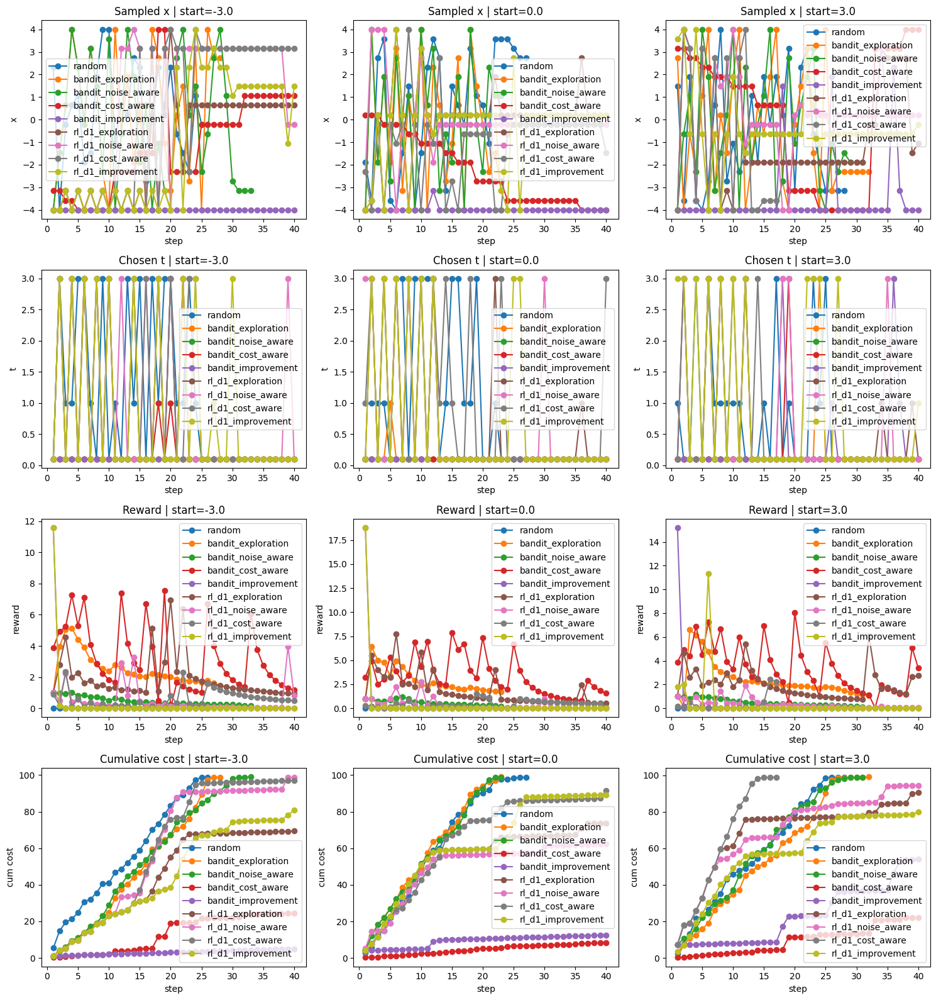

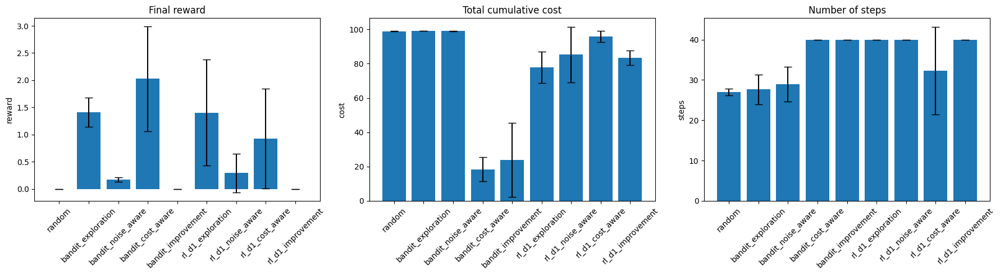

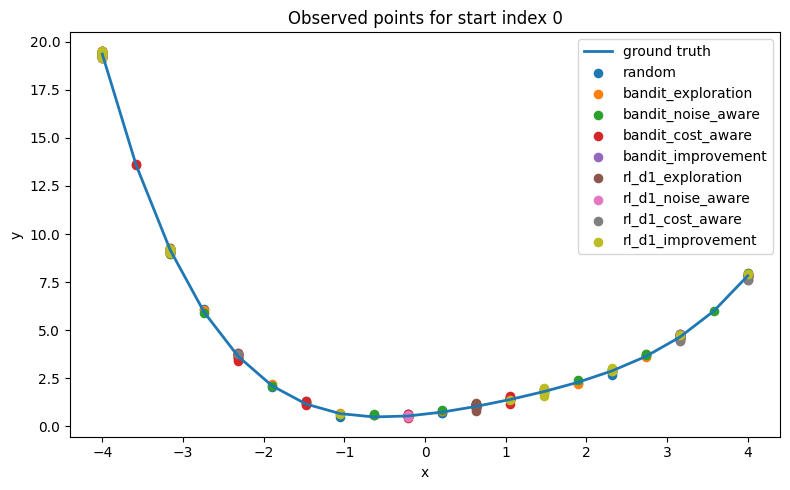

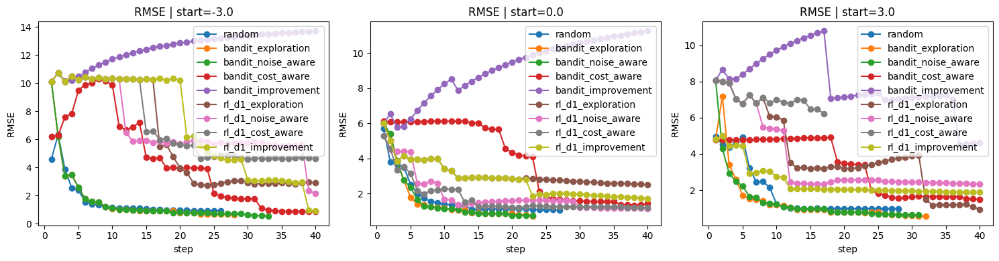

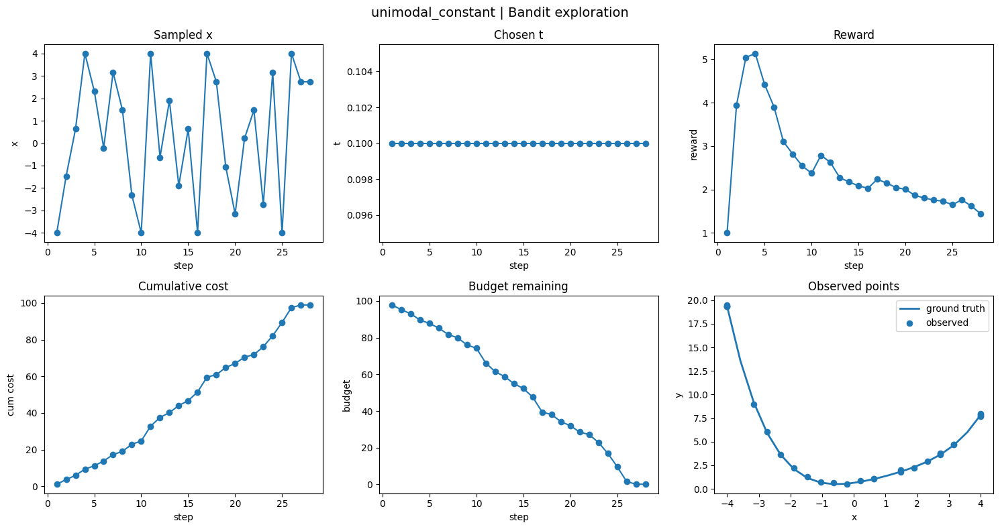

In [41]:
case_key = "unimodal_constant"

problem = all_runs[case_key]["problem"]
results = all_runs[case_key]["results"]

plot_method_comparison(results, problem, start_points=[-3.0, 0.0, 3.0])
plot_summary_bars(results)
plot_final_observations(results, problem, start_index=0)
plot_rmse_comparison(results, start_points=[-3.0, 0.0, 3.0])
plot_single_trajectory(results["bandit_exploration"][0], problem, title=f"{case_key} | Bandit exploration")

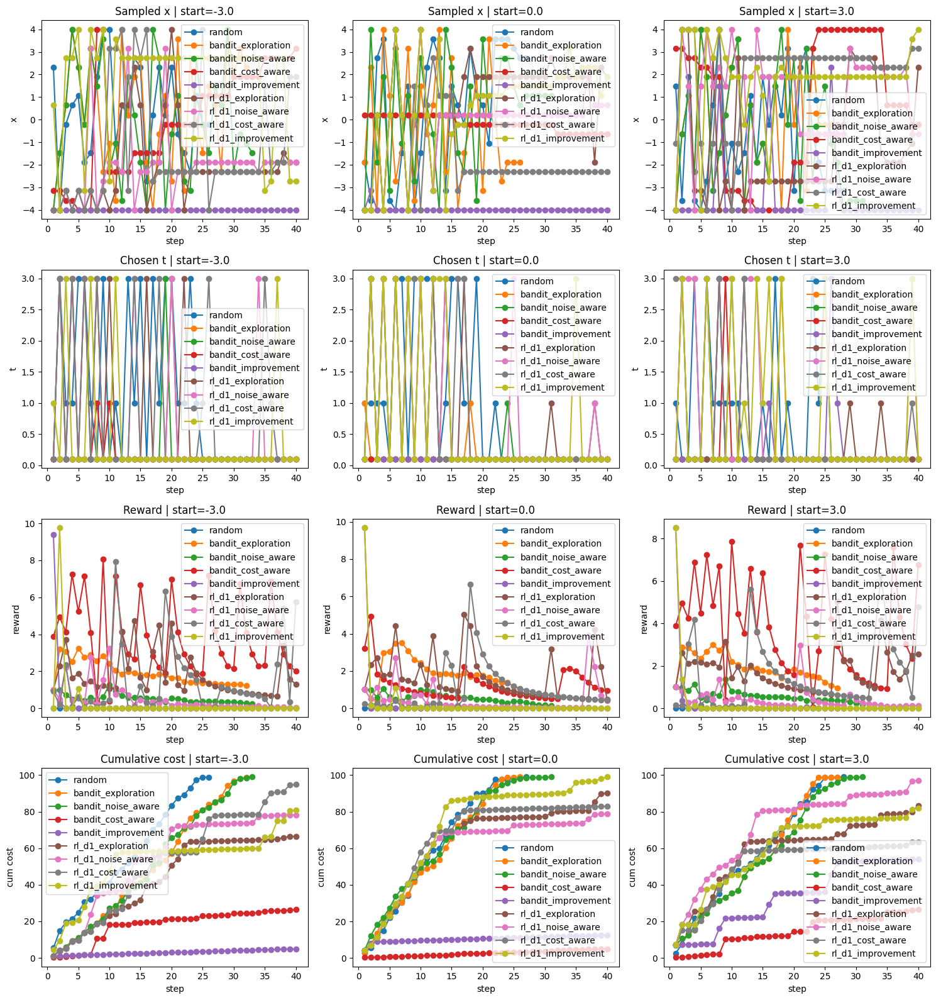

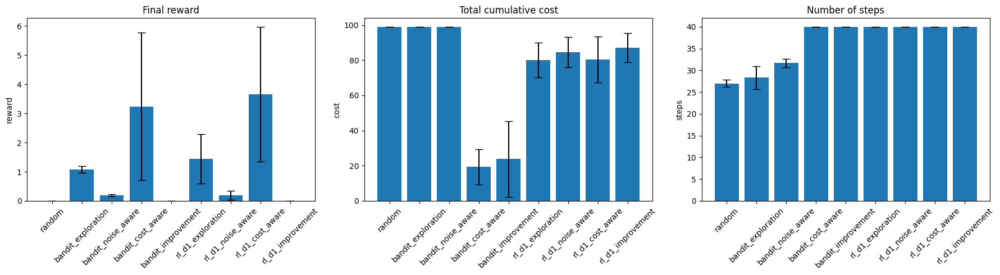

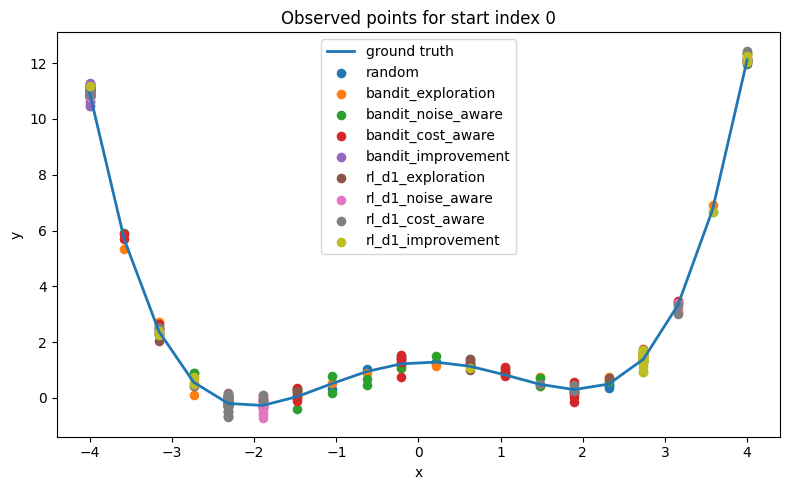

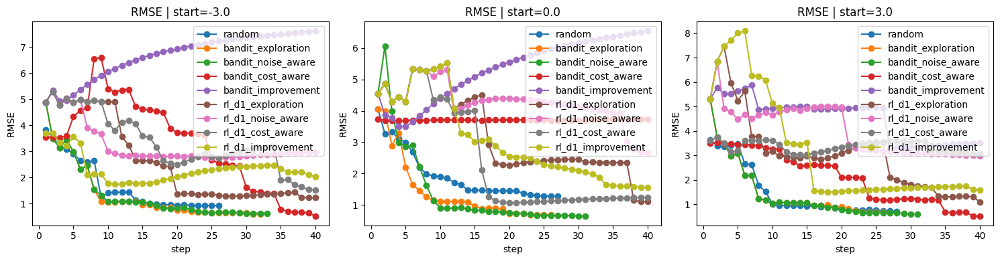

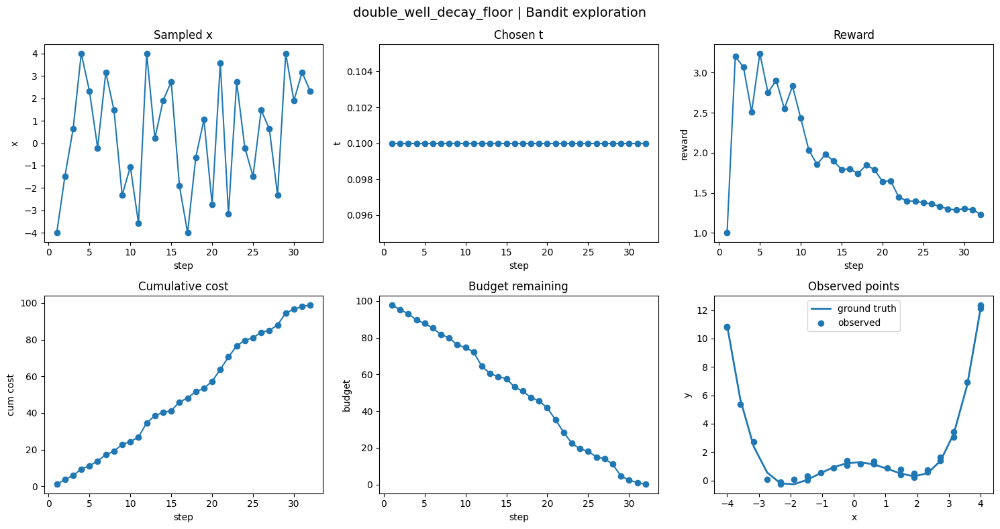

In [42]:
case_key = "double_well_decay_floor"

problem = all_runs[case_key]["problem"]
results = all_runs[case_key]["results"]

plot_method_comparison(results, problem, start_points=[-3.0, 0.0, 3.0])
plot_summary_bars(results)
plot_final_observations(results, problem, start_index=0)
plot_rmse_comparison(results, start_points=[-3.0, 0.0, 3.0])
plot_single_trajectory(results["bandit_exploration"][0], problem, title=f"{case_key} | Bandit exploration")

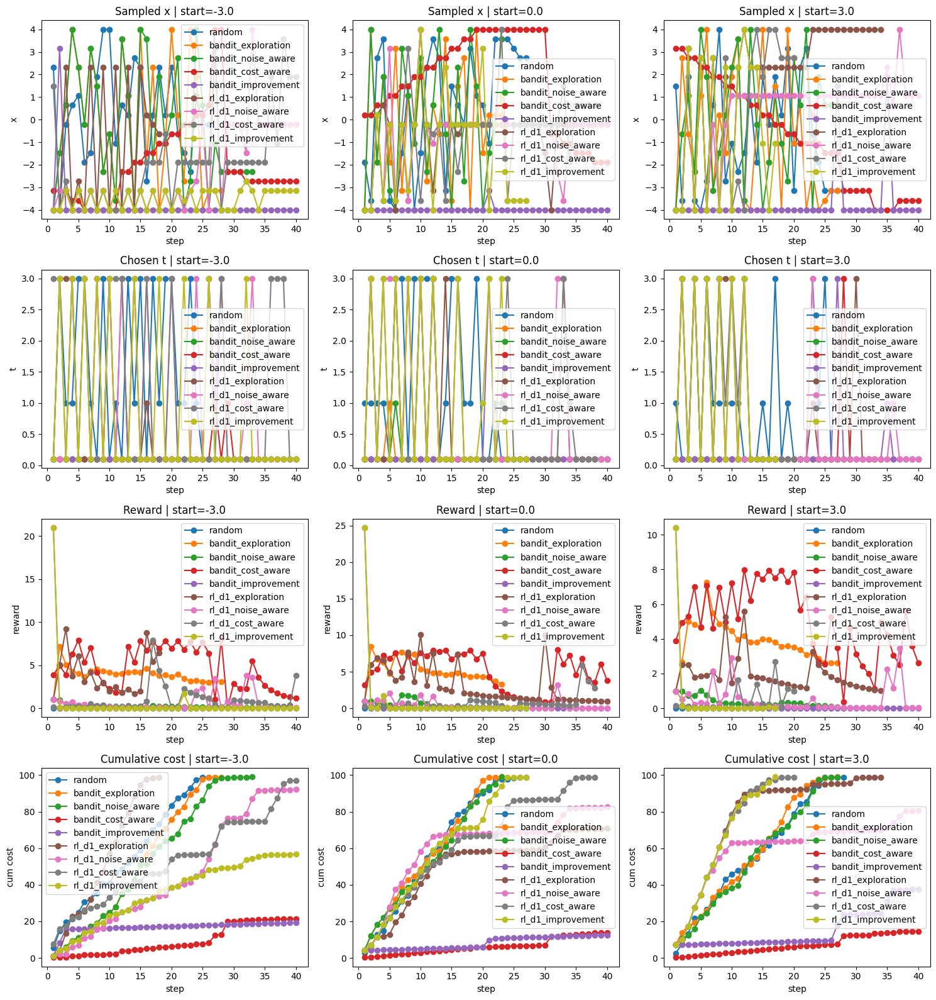

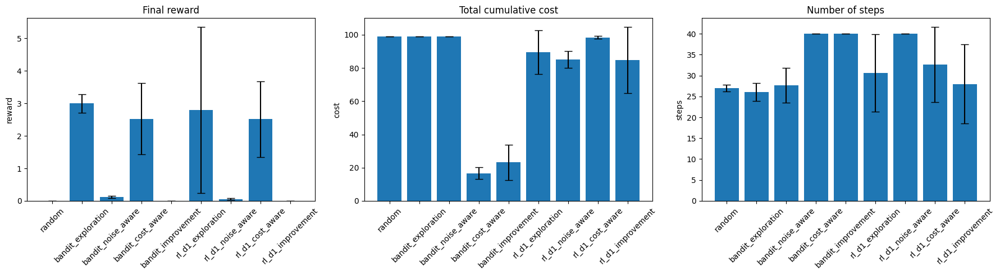

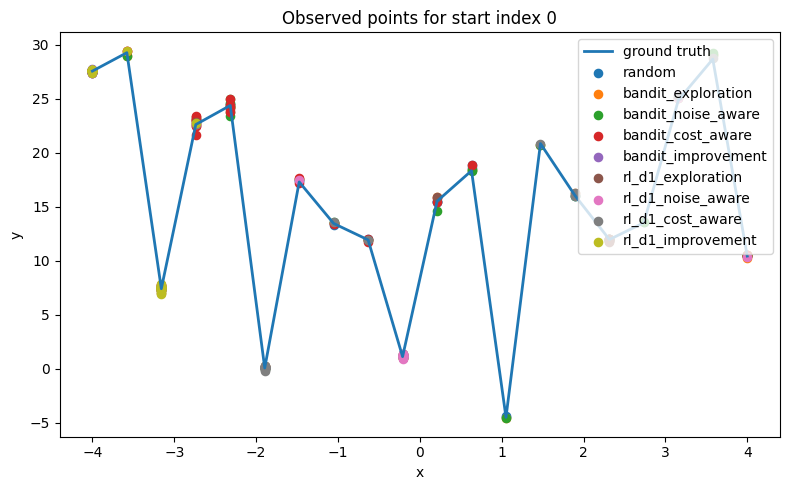

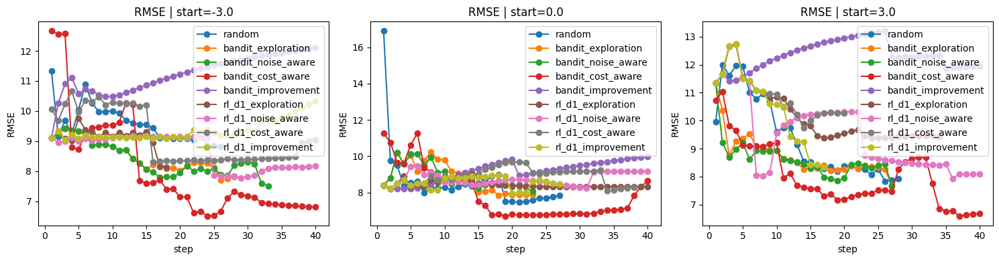

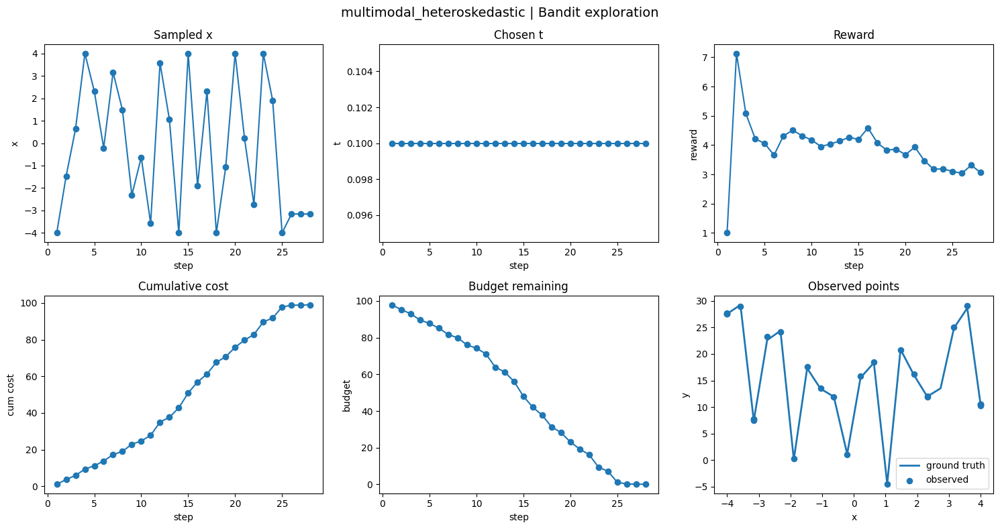

In [43]:
case_key = "multimodal_heteroskedastic"

problem = all_runs[case_key]["problem"]
results = all_runs[case_key]["results"]

plot_method_comparison(results, problem, start_points=[-3.0, 0.0, 3.0])
plot_summary_bars(results)
plot_final_observations(results, problem, start_index=0)
plot_rmse_comparison(results, start_points=[-3.0, 0.0, 3.0])
plot_single_trajectory(results["bandit_exploration"][0], problem, title=f"{case_key} | Bandit exploration")

# Simulations with measurement time a feature  in GP

In [49]:
import numpy as np
import torch
import gpytorch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ---------------------------------------------------------
# EXACT GP MODEL
# ---------------------------------------------------------
class ExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        input_dim = train_x.shape[-1]

        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(nu=1.5, ard_num_dims=input_dim)
        )

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)


# ---------------------------------------------------------
# GP HELPER
# ---------------------------------------------------------
class GPHelper:
    def __init__(self, lr=0.05, iters=20, input_dim=2):
        self.lr = lr
        self.iters = iters
        self.input_dim = input_dim

        self.model = None
        self.likelihood = None

        self.x_mean = None
        self.x_std = None
        self.y_mean = None
        self.y_std = None

    def _ensure_2d(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim == 0:
            raise ValueError("Input must not be scalar.")

        if X.ndim == 1:
            if X.shape[0] == self.input_dim:
                X = X.reshape(1, self.input_dim)
            else:
                if X.shape[0] % self.input_dim != 0:
                    raise ValueError(
                        f"1D input of length {X.shape[0]} cannot be reshaped into (?, {self.input_dim})"
                    )
                X = X.reshape(-1, self.input_dim)

        if X.ndim != 2:
            raise ValueError(f"Expected 2D input, got shape {X.shape}")

        if X.shape[1] != self.input_dim:
            raise ValueError(
                f"Expected input dimension {self.input_dim}, got shape {X.shape}"
            )

        return X

    def fit(self, X_train, y_train):
        X_train = self._ensure_2d(X_train)
        y_train = np.asarray(y_train, dtype=float).reshape(-1)

        if X_train.shape[0] != len(y_train):
            raise ValueError(
                f"X_train rows ({X_train.shape[0]}) must match y_train length ({len(y_train)})"
            )

        self.x_mean = X_train.mean(axis=0, keepdims=True)
        self.x_std = X_train.std(axis=0, keepdims=True) + 1e-8
        self.y_mean = float(y_train.mean())
        self.y_std = float(y_train.std()) + 1e-8

        Xn = (X_train - self.x_mean) / self.x_std
        yn = (y_train - self.y_mean) / self.y_std

        train_x = torch.tensor(Xn, dtype=torch.float32, device=device)
        train_y = torch.tensor(yn, dtype=torch.float32, device=device).reshape(-1)

        self.likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device)
        self.model = ExactGPModel(train_x, train_y, self.likelihood).to(device)

        self.model.train()
        self.likelihood.train()

        optimizer = torch.optim.Adam(self.model.parameters(), lr=self.lr)
        mll = gpytorch.mlls.ExactMarginalLogLikelihood(self.likelihood, self.model)

        for _ in range(self.iters):
            optimizer.zero_grad()
            output = self.model(train_x)
            loss = -mll(output, train_y)
            loss.backward()
            optimizer.step()

    def predict(self, X_test):
        if self.model is None:
            raise RuntimeError("Call fit() before predict().")

        X_test = self._ensure_2d(X_test)
        Xn = (X_test - self.x_mean) / self.x_std

        test_x = torch.tensor(Xn, dtype=torch.float32, device=device)

        self.model.eval()
        self.likelihood.eval()

        with torch.no_grad(), gpytorch.settings.fast_pred_var():
            pred = self.likelihood(self.model(test_x))

        mean = pred.mean.detach().cpu().numpy().reshape(-1)
        std = pred.stddev.detach().cpu().numpy().reshape(-1)

        mean = mean * self.y_std + self.y_mean
        std = std * self.y_std

        noise_var = float(self.likelihood.noise.detach().cpu().item())
        noise_std = np.full(mean.shape, np.sqrt(noise_var) * self.y_std, dtype=float)

        return mean, std, noise_std


# ---------------------------------------------------------
# FEATURES + Q MODEL
# ---------------------------------------------------------
def featurize(state, x, t, gp_mean, gp_std, noise_std, cost):
    return np.array([
        x,
        t,
        state["x_current"],
        state["budget_remaining"],
        gp_mean,
        gp_std,
        noise_std,
        cost
    ], dtype=float)


class LinearQ:
    def __init__(self, dim=8, lr=0.01):
        self.w = torch.zeros(dim, dtype=torch.float32, device=device)
        self.lr = lr

    def predict(self, phi):
        phi_t = torch.tensor(phi, dtype=torch.float32, device=device)
        return float(torch.dot(self.w, phi_t).item())

    def update(self, phi, target):
        phi_t = torch.tensor(phi, dtype=torch.float32, device=device)
        target_t = torch.tensor(float(target), dtype=torch.float32, device=device)
        pred = torch.dot(self.w, phi_t)
        self.w += self.lr * (target_t - pred) * phi_t


# ---------------------------------------------------------
# SMALL HELPERS FOR 2D GP INPUT = (x, t)
# ---------------------------------------------------------
def build_train_inputs(state):
    x_train = np.asarray(state["X_obs"], dtype=float).reshape(-1)
    t_train = np.asarray(state["T_obs"], dtype=float).reshape(-1)
    y_train = np.asarray(state["Y_obs"], dtype=float).reshape(-1)

    if len(x_train) == 0:
        return None, y_train

    if not (len(x_train) == len(t_train) == len(y_train)):
        raise ValueError(
            f"Mismatched train lengths: len(x)={len(x_train)}, len(t)={len(t_train)}, len(y)={len(y_train)}"
        )

    X_train = np.column_stack([x_train, t_train])
    return X_train, y_train


def build_test_inputs(x_values, t_value):
    x_values = np.asarray(x_values, dtype=float).reshape(-1)
    t_col = np.full(x_values.shape, float(t_value), dtype=float)
    X_test = np.column_stack([x_values, t_col])
    return X_test


# ---------------------------------------------------------
# REWARD SELECTION
# ---------------------------------------------------------
def compute_reward(
    reward_name,
    reward_fn,
    y_next=None,
    y_best_prev=None,
    gp_std=None,
    noise_std=None,
    action_cost=None,
    old_std=None,
    new_std=None,
):
    if reward_name == "exploration":
        return reward_fn.exploration_proxy(gp_std)

    elif reward_name == "noise_aware":
        return reward_fn.noise_aware_information(
            gp_std_at_x=gp_std,
            noise_std_at_x_t=noise_std
        )

    elif reward_name == "cost_aware":
        info = reward_fn.noise_aware_information(
            gp_std_at_x=gp_std,
            noise_std_at_x_t=noise_std
        )
        return reward_fn.cost_aware_information(
            info_gain=info,
            action_cost=action_cost
        )

    elif reward_name == "improvement":
        return reward_fn.improvement_in_best(
            y_next=y_next,
            y_best_prev=y_best_prev
        )

    elif reward_name == "global_variance_reduction":
        if old_std is None or new_std is None:
            raise ValueError("old_std and new_std are required")
        return reward_fn.global_variance_reduction(old_std=old_std, new_std=new_std)

    else:
        raise ValueError(f"Unknown reward_name: {reward_name}")


# ---------------------------------------------------------
# GP RMSE
# ---------------------------------------------------------
def evaluate_current_gp_rmse(env, problem, gp_helper, t_ref=None):
    state = env.get_state()

    x_test = problem.x_grid
    y_true = problem.ground_truth_model(x_test)

    if t_ref is None:
        t_ref = float(max(problem.t_choices))

    X_train, y_train = build_train_inputs(state)

    if X_train is None or len(y_train) < 2:
        mean = np.full_like(x_test, np.mean(y_train) if len(y_train) > 0 else 0.0, dtype=float)
        rmse = np.sqrt(np.mean((mean - y_true) ** 2))
        avg_std = 1.0
        return {
            "mean": mean,
            "rmse": float(rmse),
            "avg_std": float(avg_std),
        }

    gp_helper.fit(X_train, y_train)
    X_test = build_test_inputs(x_test, t_ref)
    mean, std, noise_std = gp_helper.predict(X_test)

    rmse = np.sqrt(np.mean((mean - y_true) ** 2))
    avg_std = float(np.mean(std))

    return {
        "mean": mean,
        "rmse": float(rmse),
        "avg_std": avg_std,
    }


# ---------------------------------------------------------
# GP PRECOMPUTE HELPERS
# ---------------------------------------------------------
def precompute_gp_maps(state, problem, gp_helper):
    means, stds, noises = {}, {}, {}
    x_grid = problem.x_grid

    X_train, y_train = build_train_inputs(state)

    if X_train is None or len(y_train) == 0:
        for t in problem.t_choices:
            means[t] = np.zeros_like(x_grid, dtype=float)
            stds[t] = np.ones_like(x_grid, dtype=float)
            noises[t] = np.ones_like(x_grid, dtype=float)
        return means, stds, noises

    gp_helper.fit(X_train, y_train)

    for t in problem.t_choices:
        X_test = build_test_inputs(x_grid, t)
        mean, std, noise_std = gp_helper.predict(X_test)
        means[t] = mean.copy()
        stds[t] = std.copy()
        noises[t] = noise_std.copy()

    return means, stds, noises


def max_q_over_feasible_actions(state, env, problem, q_model, gp_helper):
    means, stds, noises = precompute_gp_maps(state, problem, gp_helper)
    best_q = -np.inf

    for i, x in enumerate(problem.x_grid):
        for t in problem.t_choices:
            if not env.is_feasible(x, t):
                continue

            cost = env.total_cost(x, t)
            phi = featurize(
                state, x, t,
                gp_mean=float(means[t][i]),
                gp_std=float(stds[t][i]),
                noise_std=float(noises[t][i]),
                cost=cost
            )
            q_val = q_model.predict(phi)
            best_q = max(best_q, q_val)

    return 0.0 if best_q == -np.inf else best_q


def compute_backup_target(rewards, future_q, gamma, depth):
    if depth < 0:
        raise ValueError("depth must be >= 0")

    discounted_reward_sum = 0.0
    for k, r in enumerate(rewards):
        discounted_reward_sum += (gamma ** k) * r

    if depth == 0:
        return rewards[0]

    return discounted_reward_sum + (gamma ** len(rewards)) * future_q


# ---------------------------------------------------------
# POLICIES
# ---------------------------------------------------------
class RandomMeasurementPolicy:
    def select_action(self, env, problem):
        feasible_actions = [
            (float(x), float(t))
            for x in problem.x_grid
            for t in problem.t_choices
            if env.is_feasible(x, t)
        ]
        if len(feasible_actions) == 0:
            raise ValueError("No feasible action found")
        action = feasible_actions[np.random.randint(len(feasible_actions))]
        return action, None


class BanditPolicy:
    def __init__(self, gp_helper, reward_fn, reward_name="cost_aware", epsilon=0.1):
        self.gp_helper = gp_helper
        self.reward_fn = reward_fn
        self.reward_name = reward_name
        self.epsilon = epsilon

    def _compute_score(
        self,
        state,
        mean_val,
        std_val,
        noise_val,
        cost,
        old_std_grid=None,
        new_std_grid=None,
    ):
        if self.reward_name == "exploration":
            return self.reward_fn.exploration_proxy(std_val)

        elif self.reward_name == "noise_aware":
            return self.reward_fn.noise_aware_information(
                gp_std_at_x=std_val,
                noise_std_at_x_t=noise_val
            )

        elif self.reward_name == "cost_aware":
            info = self.reward_fn.noise_aware_information(
                gp_std_at_x=std_val,
                noise_std_at_x_t=noise_val
            )
            return self.reward_fn.cost_aware_information(
                info_gain=info,
                action_cost=cost
            )

        elif self.reward_name == "improvement":
            y_best_prev = np.max(state["Y_obs"]) if len(state["Y_obs"]) > 0 else None
            return self.reward_fn.improvement_in_best(
                y_next=mean_val,
                y_best_prev=y_best_prev
            )

        elif self.reward_name == "global_variance_reduction":
            if old_std_grid is None or new_std_grid is None:
                raise ValueError("global_variance_reduction requires old_std_grid and new_std_grid")
            return self.reward_fn.global_variance_reduction(
                old_std=old_std_grid,
                new_std=new_std_grid
            )

        else:
            raise ValueError(f"Unknown reward_name: {self.reward_name}")

    def select_action(self, env, problem):
        state = env.get_state()
        X_train, y_train = build_train_inputs(state)

        if X_train is None or len(y_train) == 0:
            x0 = float(problem.x_grid[0])
            t0 = float(problem.t_choices[0])
            cost0 = env.total_cost(x0, t0)

            phi = featurize(
                state, x0, t0,
                gp_mean=0.0,
                gp_std=1.0,
                noise_std=1.0,
                cost=cost0
            )
            return (x0, t0), phi

        means, stds, noises = precompute_gp_maps(state, problem, self.gp_helper)

        feasible_actions = [
            (float(x), float(t))
            for x in problem.x_grid
            for t in problem.t_choices
            if env.is_feasible(x, t)
        ]
        if len(feasible_actions) == 0:
            raise ValueError("No feasible action found")

        if np.random.rand() < self.epsilon:
            x_rand, t_rand = feasible_actions[np.random.randint(len(feasible_actions))]
            i = np.where(np.isclose(problem.x_grid, x_rand))[0][0]

            phi = featurize(
                state, x_rand, t_rand,
                gp_mean=float(means[t_rand][i]),
                gp_std=float(stds[t_rand][i]),
                noise_std=float(noises[t_rand][i]),
                cost=env.total_cost(x_rand, t_rand)
            )
            return (x_rand, t_rand), phi

        best_score = -np.inf
        best_action = None
        best_phi = None

        old_std_grid_cache = {}
        if self.reward_name == "global_variance_reduction":
            for t in problem.t_choices:
                old_std_grid_cache[t] = stds[t].copy()

        for i, x in enumerate(problem.x_grid):
            for t in problem.t_choices:
                if not env.is_feasible(x, t):
                    continue

                cost = env.total_cost(x, t)
                mean_val = float(means[t][i])
                std_val = float(stds[t][i])
                noise_val = float(noises[t][i])

                old_std_grid = None
                new_std_grid = None

                if self.reward_name == "global_variance_reduction":
                    X_aug = np.vstack([X_train, np.array([[x, t]], dtype=float)])
                    y_aug = np.append(y_train, mean_val)

                    temp_gp = GPHelper(
                        lr=self.gp_helper.lr,
                        iters=self.gp_helper.iters,
                        input_dim=self.gp_helper.input_dim
                    )
                    temp_gp.fit(X_aug, y_aug)

                    X_test_aug = build_test_inputs(problem.x_grid, t)
                    _, new_std_grid, _ = temp_gp.predict(X_test_aug)

                    old_std_grid = old_std_grid_cache[t]

                score = self._compute_score(
                    state=state,
                    mean_val=mean_val,
                    std_val=std_val,
                    noise_val=noise_val,
                    cost=cost,
                    old_std_grid=old_std_grid,
                    new_std_grid=new_std_grid,
                )

                phi = featurize(
                    state, x, t,
                    gp_mean=mean_val,
                    gp_std=std_val,
                    noise_std=noise_val,
                    cost=cost
                )

                if score > best_score:
                    best_score = score
                    best_action = (float(x), float(t))
                    best_phi = phi

        if best_action is None:
            raise ValueError("No feasible action found")

        return best_action, best_phi


class RLPolicy:
    def __init__(self, gp_helper, q_model, epsilon=0.1):
        self.gp_helper = gp_helper
        self.q_model = q_model
        self.epsilon = epsilon

    def select_action(self, env, problem):
        state = env.get_state()
        means, stds, noises = precompute_gp_maps(state, problem, self.gp_helper)

        feasible_actions = [
            (float(x), float(t))
            for x in problem.x_grid
            for t in problem.t_choices
            if env.is_feasible(x, t)
        ]

        if len(feasible_actions) == 0:
            raise ValueError("No feasible action found")

        if np.random.rand() < self.epsilon:
            x_rand, t_rand = feasible_actions[np.random.randint(len(feasible_actions))]
            i = np.where(np.isclose(problem.x_grid, x_rand))[0][0]

            phi = featurize(
                state, x_rand, t_rand,
                gp_mean=float(means[t_rand][i]),
                gp_std=float(stds[t_rand][i]),
                noise_std=float(noises[t_rand][i]),
                cost=env.total_cost(x_rand, t_rand)
            )
            return (x_rand, t_rand), phi

        best_q = -np.inf
        best_action = None
        best_phi = None

        for i, x in enumerate(problem.x_grid):
            for t in problem.t_choices:
                if not env.is_feasible(x, t):
                    continue

                cost = env.total_cost(x, t)
                phi = featurize(
                    state, x, t,
                    gp_mean=float(means[t][i]),
                    gp_std=float(stds[t][i]),
                    noise_std=float(noises[t][i]),
                    cost=cost
                )

                q_val = self.q_model.predict(phi)
                if q_val > best_q:
                    best_q = q_val
                    best_action = (float(x), float(t))
                    best_phi = phi

        return best_action, best_phi


# ---------------------------------------------------------
# SIMULATIONS
# ---------------------------------------------------------
def simulate_bandit_run(
    problem,
    policy,
    gp_helper,
    x_start=0.0,
    t_init=1.0,
    max_steps=200,
    verbose=False
):
    env = MeasurementEnvironment(problem)
    state = env.reset(x_start=x_start)

    if env.is_feasible(x_start, t_init):
        state, done, info = env.step((x_start, t_init))
    else:
        raise ValueError("Initial action infeasible")

    traj = {
        "x": [],
        "t": [],
        "y": [],
        "reward": [],
        "cost": [],
        "budget_remaining": [],
        "rmse": [],
        "avg_std": [],
        "gp_mean_history": [],
    }

    reward_fn = RewardFunctions()
    reward_name = getattr(policy, "reward_name", None)

    step_idx = 0
    while step_idx < max_steps:
        state = env.get_state()

        try:
            action, _ = policy.select_action(env, problem)
        except ValueError:
            break

        x_a, t_a = action
        X_train, y_train = build_train_inputs(state)

        y_best_prev = None if len(y_train) == 0 else np.max(y_train)

        if X_train is not None and len(y_train) > 0:
            gp_helper.fit(X_train, y_train)
            X_test_a = np.array([[x_a, t_a]], dtype=float)
            mean_a, std_a, noise_a = gp_helper.predict(X_test_a)
            gp_std_a = float(std_a[0])
            noise_std_a = float(noise_a[0])
        else:
            gp_std_a = 1.0
            noise_std_a = 1.0

        action_cost = env.total_cost(x_a, t_a)

        old_std_grid = None
        new_std_grid = None
        if reward_name == "global_variance_reduction" and X_train is not None and len(y_train) > 0:
            gp_helper.fit(X_train, y_train)
            X_grid_old = build_test_inputs(problem.x_grid, t_a)
            _, old_std_grid, _ = gp_helper.predict(X_grid_old)

        next_state, done, info = env.step(action)
        gp_eval = evaluate_current_gp_rmse(env, problem, gp_helper)

        traj["rmse"].append(gp_eval["rmse"])
        traj["avg_std"].append(gp_eval["avg_std"])
        traj["gp_mean_history"].append(gp_eval["mean"].copy())

        if reward_name == "global_variance_reduction":
            X_train2, y_train2 = build_train_inputs(next_state)

            if X_train2 is not None and len(y_train2) > 0:
                gp_helper.fit(X_train2, y_train2)
                X_grid_new = build_test_inputs(problem.x_grid, t_a)
                _, new_std_grid, _ = gp_helper.predict(X_grid_new)

        if reward_name is None:
            reward = 0.0
        else:
            reward = compute_reward(
                reward_name=reward_name,
                reward_fn=reward_fn,
                y_next=info["measurement"],
                y_best_prev=y_best_prev,
                gp_std=gp_std_a,
                noise_std=noise_std_a,
                action_cost=action_cost,
                old_std=old_std_grid,
                new_std=new_std_grid,
            )

        traj["x"].append(x_a)
        traj["t"].append(t_a)
        traj["y"].append(info["measurement"])
        traj["reward"].append(reward)
        traj["cost"].append(info["cost"])
        traj["budget_remaining"].append(next_state["budget_remaining"])

        if verbose:
            print(
                f"step={step_idx:02d} | x={x_a:.3f} | t={t_a:.3f} | "
                f"y={info['measurement']:.3f} | reward={reward:.4f} | "
                f"budget={next_state['budget_remaining']:.3f}"
            )

        step_idx += 1
        if done:
            break

    return traj


def simulate_rl_run(
    problem,
    policy,
    q_model,
    gp_helper,
    reward_name="cost_aware",
    gamma=0.9,
    depth=1,
    x_start=0.0,
    t_init=1.0,
    max_steps=200,
    verbose=False
):
    env = MeasurementEnvironment(problem)
    reward_fn = RewardFunctions()

    state = env.reset(x_start=x_start)

    if env.is_feasible(x_start, t_init):
        state, done, info = env.step((x_start, t_init))
    else:
        raise ValueError("Initial action infeasible")

    traj = {
        "x": [],
        "t": [],
        "y": [],
        "reward": [],
        "target": [],
        "cost": [],
        "budget_remaining": [],
        "rmse": [],
        "avg_std": [],
        "gp_mean_history": [],
    }

    step_idx = 0

    while step_idx < max_steps:
        state = env.get_state()
        try:
            action, phi = policy.select_action(env, problem)
        except ValueError:
            break
        x_a, t_a = action

        rewards_collected = []
        done = False

        for _local in range(max(1, depth)):
            state_before = env.get_state()
            y_best_prev = None if len(state_before["Y_obs"]) == 0 else np.max(state_before["Y_obs"])

            X_train, y_train = build_train_inputs(state_before)

            if X_train is not None and len(y_train) > 0:
                gp_helper.fit(X_train, y_train)
                X_test_a = np.array([[x_a, t_a]], dtype=float)
                mean_a, std_a, noise_a = gp_helper.predict(X_test_a)
                gp_std_a = float(std_a[0])
                noise_std_a = float(noise_a[0])
            else:
                gp_std_a = 1.0
                noise_std_a = 1.0

            action_cost = env.total_cost(x_a, t_a)

            old_std_grid = None
            new_std_grid = None
            if reward_name == "global_variance_reduction" and X_train is not None and len(y_train) > 0:
                gp_helper.fit(X_train, y_train)
                X_grid_old = build_test_inputs(problem.x_grid, t_a)
                _, old_std_grid, _ = gp_helper.predict(X_grid_old)

            next_state, done, info = env.step((x_a, t_a))

            if reward_name == "global_variance_reduction":
                X_train2, y_train2 = build_train_inputs(next_state)

                if X_train2 is not None and len(y_train2) > 0:
                    gp_helper.fit(X_train2, y_train2)
                    X_grid_new = build_test_inputs(problem.x_grid, t_a)
                    _, new_std_grid, _ = gp_helper.predict(X_grid_new)

            reward = compute_reward(
                reward_name=reward_name,
                reward_fn=reward_fn,
                y_next=info["measurement"],
                y_best_prev=y_best_prev,
                gp_std=gp_std_a,
                noise_std=noise_std_a,
                action_cost=action_cost,
                old_std=old_std_grid,
                new_std=new_std_grid,
            )
            rewards_collected.append(reward)

            traj["x"].append(x_a)
            traj["t"].append(t_a)
            traj["y"].append(info["measurement"])
            traj["reward"].append(reward)
            traj["cost"].append(info["cost"])
            traj["budget_remaining"].append(next_state["budget_remaining"])

            gp_eval = evaluate_current_gp_rmse(env, problem, gp_helper)
            traj["rmse"].append(gp_eval["rmse"])
            traj["avg_std"].append(gp_eval["avg_std"])
            traj["gp_mean_history"].append(gp_eval["mean"].copy())

            if verbose:
                print(
                    f"step={step_idx:02d} | x={x_a:.3f} | t={t_a:.3f} | "
                    f"y={info['measurement']:.3f} | reward={reward:.4f} | "
                    f"budget={next_state['budget_remaining']:.3f}"
                )

            step_idx += 1

            if done or step_idx >= max_steps or depth == 0:
                break

            try:
                action_next, _ = policy.select_action(env, problem)
            except ValueError:
                done = True
                break

            x_a, t_a = action_next

        future_q = 0.0 if done else max_q_over_feasible_actions(
            state=env.get_state(),
            env=env,
            problem=problem,
            q_model=q_model,
            gp_helper=gp_helper
        )

        target = compute_backup_target(
            rewards=rewards_collected,
            future_q=future_q,
            gamma=gamma,
            depth=depth
        )

        q_model.update(phi, target)
        traj["target"].append(target)

        if done:
            break

    return traj


# ---------------------------------------------------------
# DRIVER
# ---------------------------------------------------------
def run_all_scenarios(
    problem,
    start_points,
    reward_names=("exploration", "noise_aware", "cost_aware", "improvement"),
    include_global_variance=False,
    include_random=True,
    include_bandit=True,
    include_rl=True,
    rl_depth=1,
    gamma=0.9,
    t_init=1.0,
    max_steps=50,
    gp_lr=0.05,
    gp_iters=20,
    q_lr=0.01,
    epsilon_bandit=0.05,
    epsilon_rl=0.10,
    seed=123,
    verbose=False
):
    np.random.seed(seed)
    torch.manual_seed(seed)

    reward_list = list(reward_names)
    if include_global_variance and "global_variance_reduction" not in reward_list:
        reward_list.append("global_variance_reduction")

    results = {}
    rewards = RewardFunctions()

    if include_random:
        results["random"] = []
        for x0 in start_points:
            gp_helper = GPHelper(lr=gp_lr, iters=gp_iters, input_dim=2)
            random_policy = RandomMeasurementPolicy()

            traj = simulate_bandit_run(
                problem=problem,
                policy=random_policy,
                gp_helper=gp_helper,
                x_start=x0,
                t_init=t_init,
                max_steps=max_steps,
                verbose=verbose
            )
            results["random"].append(traj)

    if include_bandit:
        for reward_name in reward_list:
            method_name = f"bandit_{reward_name}"
            results[method_name] = []

            for x0 in start_points:
                gp_helper = GPHelper(lr=gp_lr, iters=gp_iters, input_dim=2)
                bandit_policy = BanditPolicy(
                    gp_helper=gp_helper,
                    reward_fn=rewards,
                    reward_name=reward_name,
                    epsilon=epsilon_bandit
                )

                traj = simulate_bandit_run(
                    problem=problem,
                    policy=bandit_policy,
                    gp_helper=gp_helper,
                    x_start=x0,
                    t_init=t_init,
                    max_steps=max_steps,
                    verbose=verbose
                )
                results[method_name].append(traj)

    if include_rl:
        for reward_name in reward_list:
            method_name = f"rl_d{rl_depth}_{reward_name}"
            results[method_name] = []

            for x0 in start_points:
                gp_helper = GPHelper(lr=gp_lr, iters=gp_iters, input_dim=2)
                q_model = LinearQ(dim=8, lr=q_lr)
                rl_policy = RLPolicy(
                    gp_helper=gp_helper,
                    q_model=q_model,
                    epsilon=epsilon_rl
                )

                traj = simulate_rl_run(
                    problem=problem,
                    policy=rl_policy,
                    q_model=q_model,
                    gp_helper=gp_helper,
                    reward_name=reward_name,
                    gamma=gamma,
                    depth=rl_depth,
                    x_start=x0,
                    t_init=t_init,
                    max_steps=max_steps,
                    verbose=verbose
                )
                results[method_name].append(traj)

    return results


# ---------------------------------------------------------
# MULTI-CASE RUNNER
# ---------------------------------------------------------
ground_truth_cases = {
    "unimodal": unimodal,
    "double_well": double_well,
    "multimodal": multimodal,
    "broad_narrow": broad_narrow,
}

noise_cases = {
    "constant": noise_constant,
    "decay_floor": noise_decay_floor,
}

start_points = [-3.0, 0.0, 3.0]


def build_problem(gt_fn, noise_fn, t_choices=(0.1, 1.0, 3.0), budget=100.0):
    return MeasurementProblemDefinition(
        budget=budget,
        ground_truth_model=gt_fn,
        noise_model=noise_fn,
        rng_seed=123,
        x_domain=(-4.0, 4.0),
        x_grid_size=20,
        t_choices=t_choices,
    )


def run_case(
    case_name,
    gt_fn,
    noise_fn,
    t_choices=(0.1, 1.0, 3.0),
    rl_depth=1,
    budget=100.0,
    max_steps=40,
    verbose=False,
):
    print(f"\nRunning: {case_name}")

    problem = build_problem(
        gt_fn=gt_fn,
        noise_fn=noise_fn,
        t_choices=t_choices,
        budget=budget,
    )

    results = run_all_scenarios(
        problem=problem,
        start_points=start_points,
        reward_names=("exploration", "noise_aware", "cost_aware", "improvement"),
        include_global_variance=False,
        include_random=True,
        include_bandit=True,
        include_rl=True,
        rl_depth=rl_depth,
        gamma=0.9,
        t_init=1.0,
        max_steps=max_steps,
        gp_lr=0.05,
        gp_iters=20,
        q_lr=0.01,
        epsilon_bandit=0.05,
        epsilon_rl=0.10,
        seed=123,
        verbose=verbose,
    )

    return problem, results



In [50]:

# ---------------------------------------------------------
# EXAMPLE: RUN 3 RECOMMENDED CASES
# ---------------------------------------------------------
all_runs = {}

problem_u, results_u = run_case(
    case_name="unimodal_constant",
    gt_fn=unimodal,
    noise_fn=noise_constant,
    t_choices=(0.1, 1.0, 3.0),
    rl_depth=1,
)
all_runs["unimodal_constant"] = {"problem": problem_u, "results": results_u}

problem_d, results_d = run_case(
    case_name="double_well_decay_floor",
    gt_fn=double_well,
    noise_fn=noise_decay_floor,
    t_choices=(0.1, 1.0, 3.0),
    rl_depth=1,
)
all_runs["double_well_decay_floor"] = {"problem": problem_d, "results": results_d}

hetero_multimodal = make_heteroskedastic_noise_model(multimodal, (-4, 4))
problem_m, results_m = run_case(
    case_name="multimodal_heteroskedastic",
    gt_fn=multimodal,
    noise_fn=hetero_multimodal,
    t_choices=(0.1, 1.0, 3.0),
    rl_depth=1,
)
all_runs["multimodal_heteroskedastic"] = {"problem": problem_m, "results": results_m}




Running: unimodal_constant

Running: double_well_decay_floor

Running: multimodal_heteroskedastic


In [51]:

# # ---------------------------------------------------------
# # EXAMPLE: PLOT ONE CASE
# # ---------------------------------------------------------
# case_key = "double_well_decay_floor"

# problem = all_runs[case_key]["problem"]
# results = all_runs[case_key]["results"]

# plot_method_comparison(results, problem, start_points=start_points)
# plot_summary_bars(results)
# plot_final_observations(results, problem, start_index=0)
# plot_rmse_comparison(results, start_points=start_points)
# plot_single_trajectory(
#     results["bandit_exploration"][0],
#     problem,
#     title=f"{case_key} | Bandit exploration"
# )

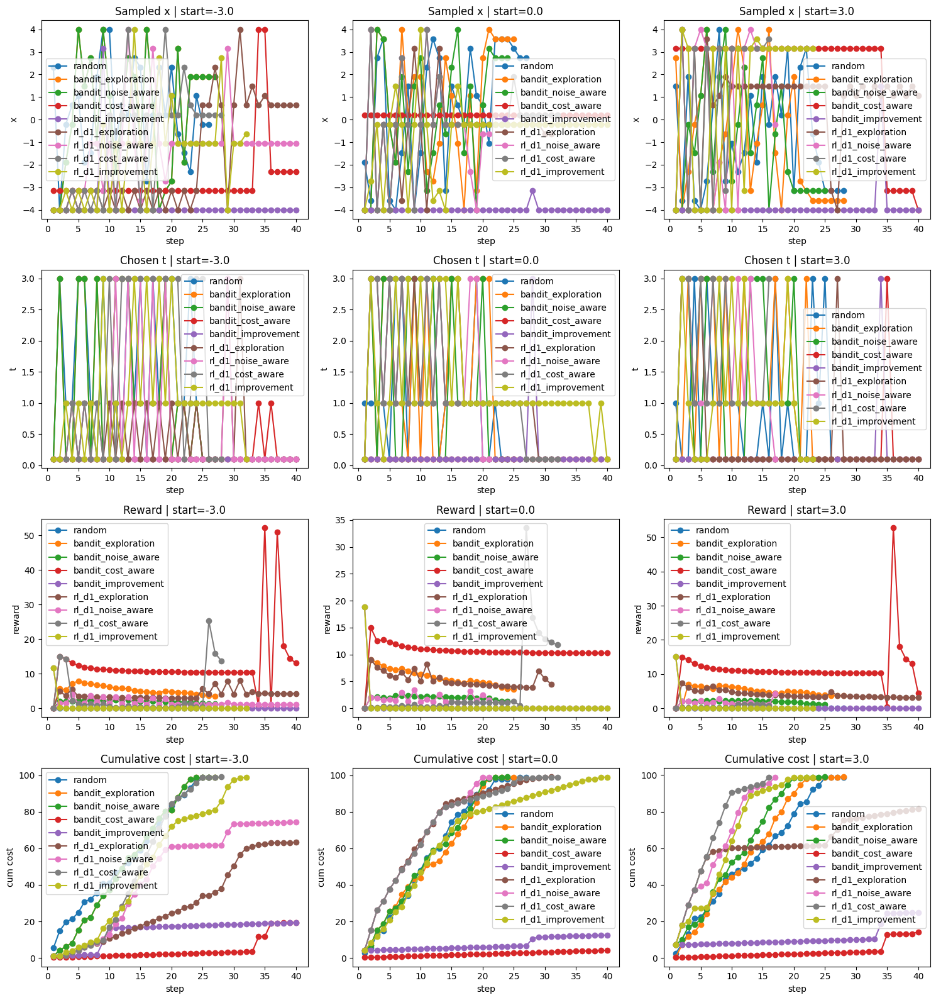

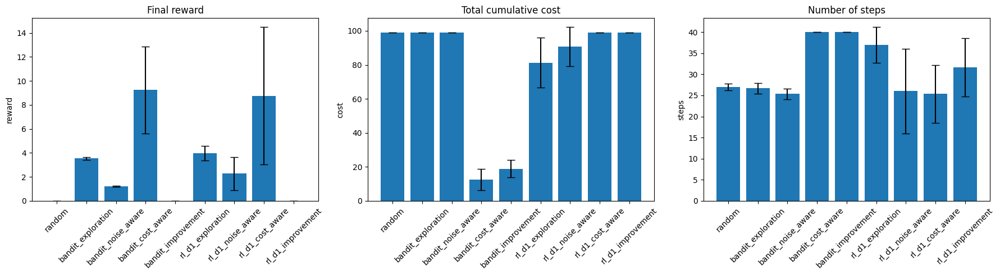

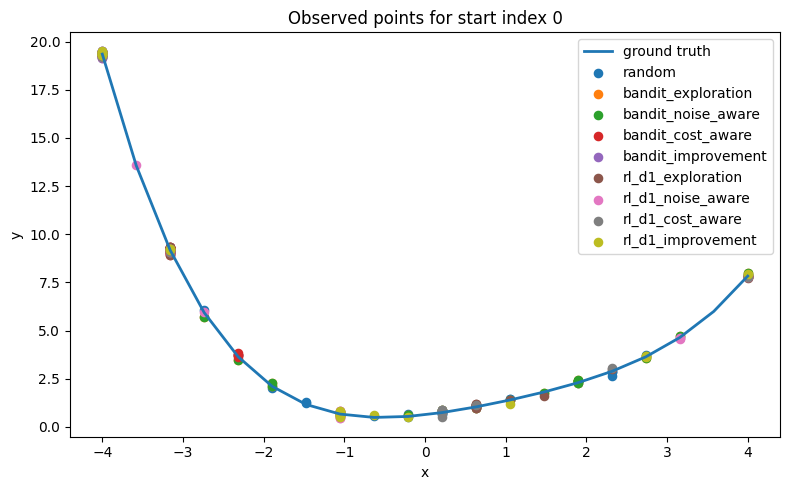

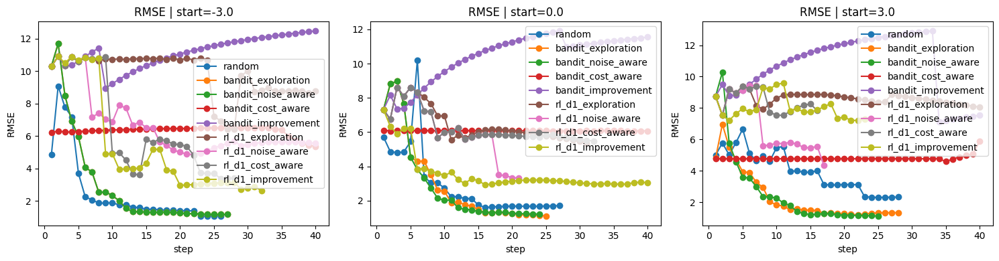

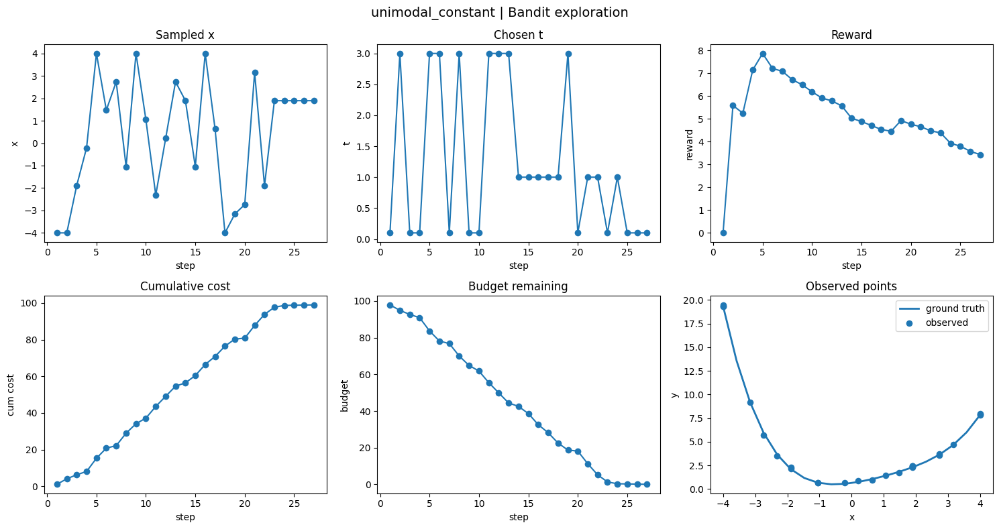

In [52]:
case_key = "unimodal_constant"

problem = all_runs[case_key]["problem"]
results = all_runs[case_key]["results"]

plot_method_comparison(results, problem, start_points=start_points)
plot_summary_bars(results)
plot_final_observations(results, problem, start_index=0)
plot_rmse_comparison(results, start_points=start_points)
plot_single_trajectory(
    results["bandit_exploration"][0],
    problem,
    title=f"{case_key} | Bandit exploration"
)

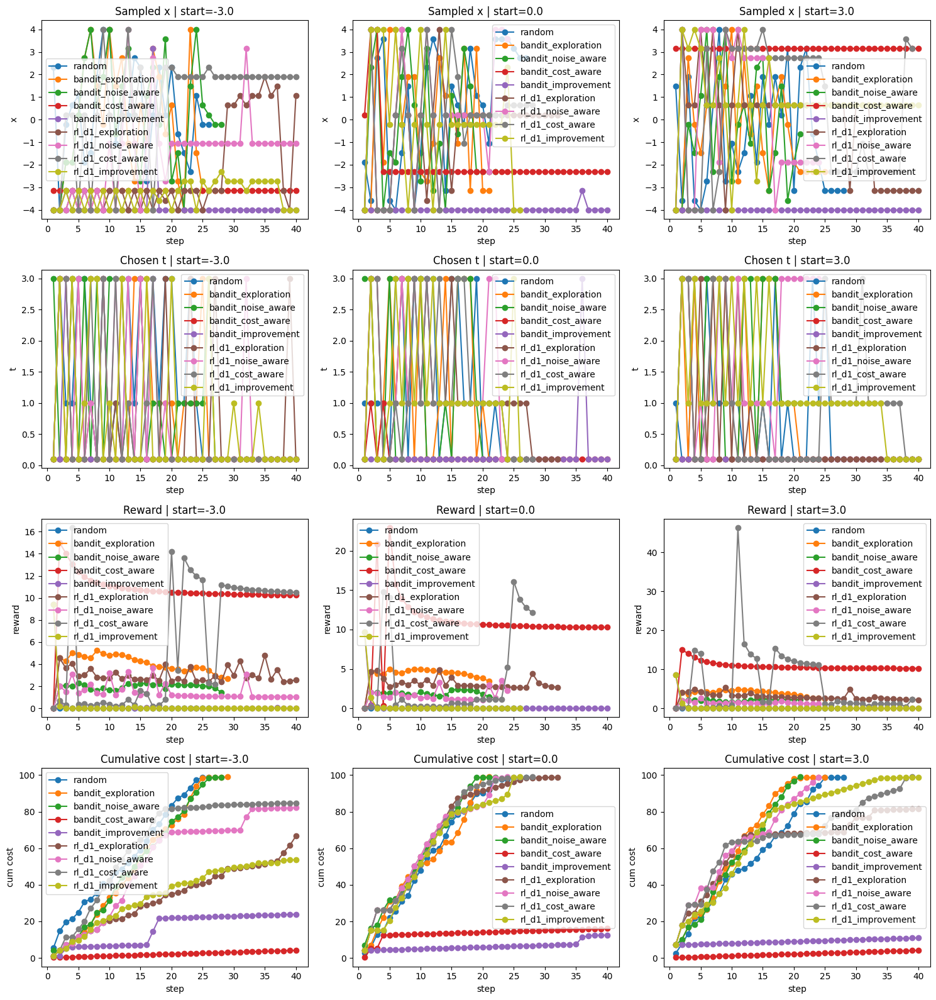

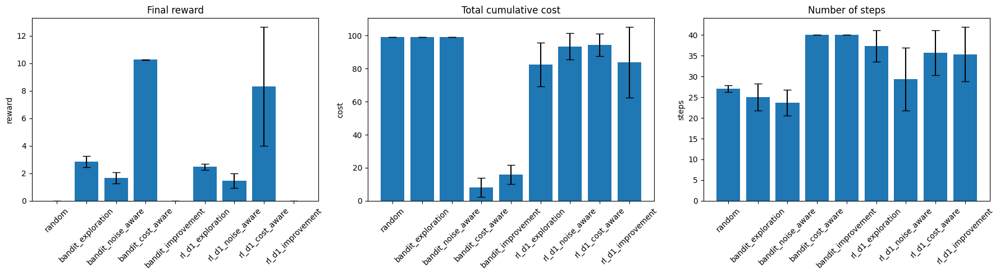

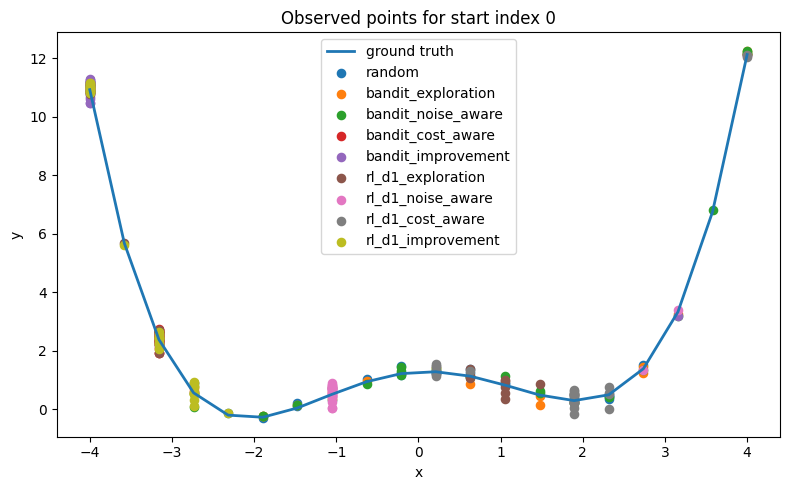

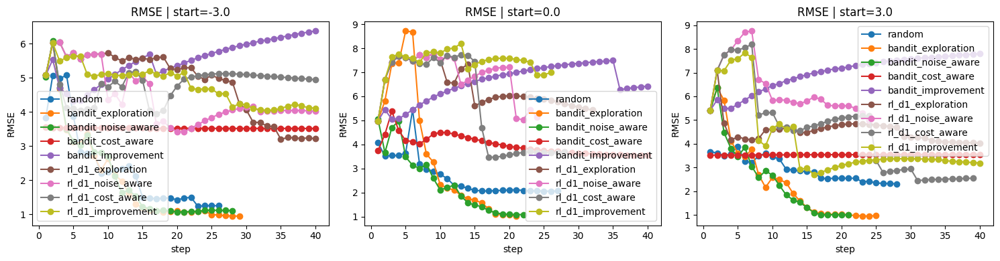

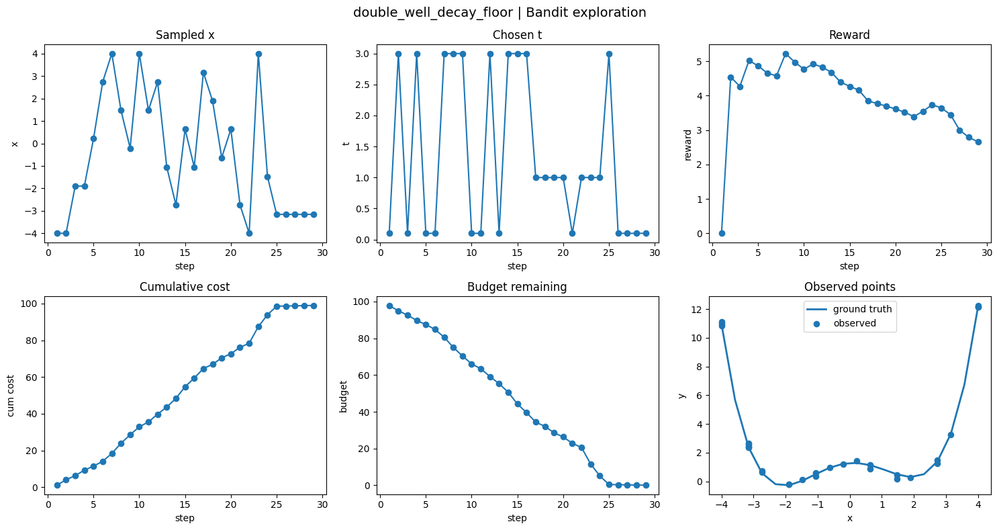

In [53]:

case_key = "double_well_decay_floor"

problem = all_runs[case_key]["problem"]
results = all_runs[case_key]["results"]

plot_method_comparison(results, problem, start_points=start_points)
plot_summary_bars(results)
plot_final_observations(results, problem, start_index=0)
plot_rmse_comparison(results, start_points=start_points)
plot_single_trajectory(
    results["bandit_exploration"][0],
    problem,
    title=f"{case_key} | Bandit exploration"
)

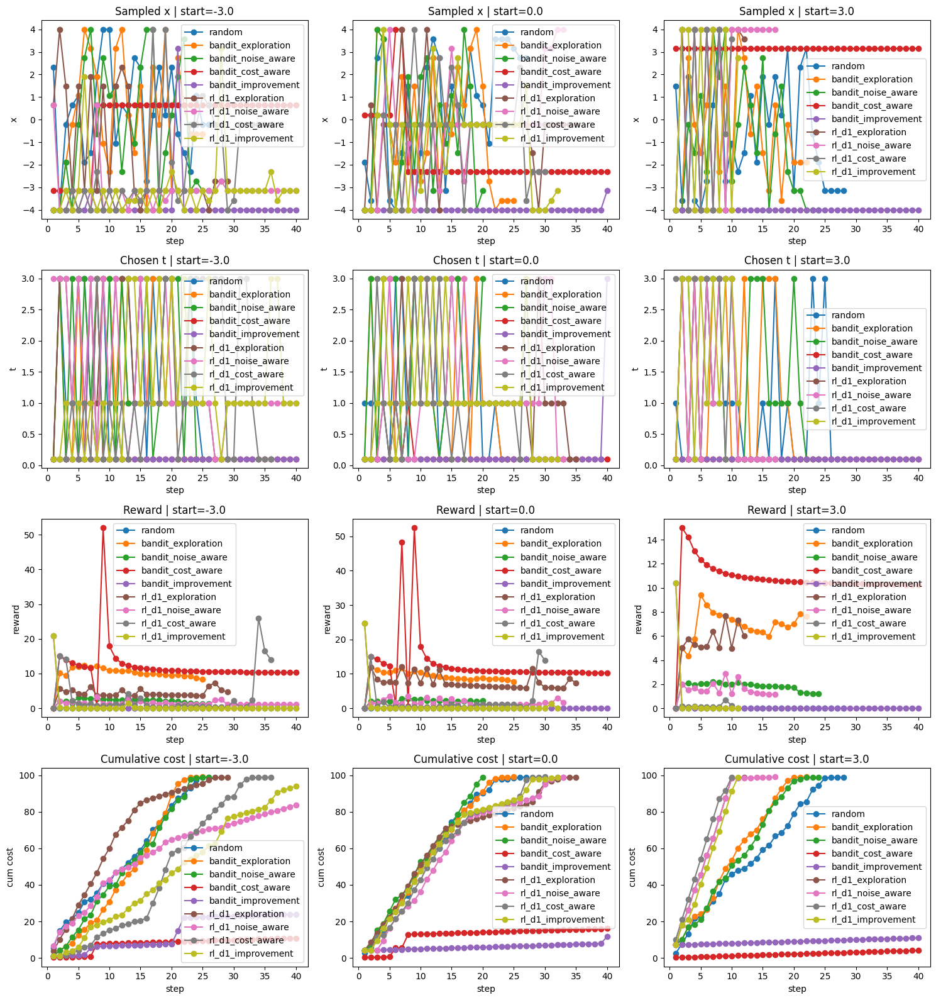

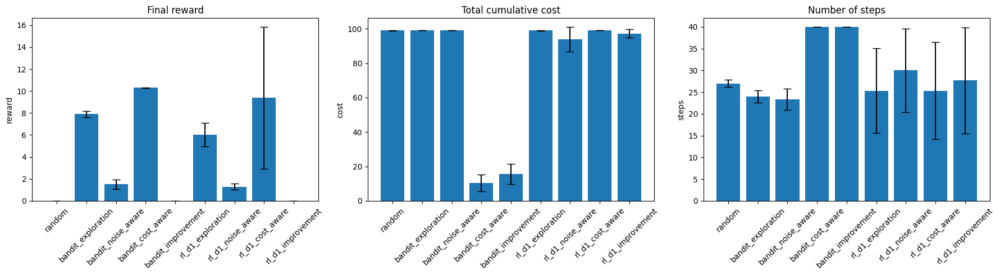

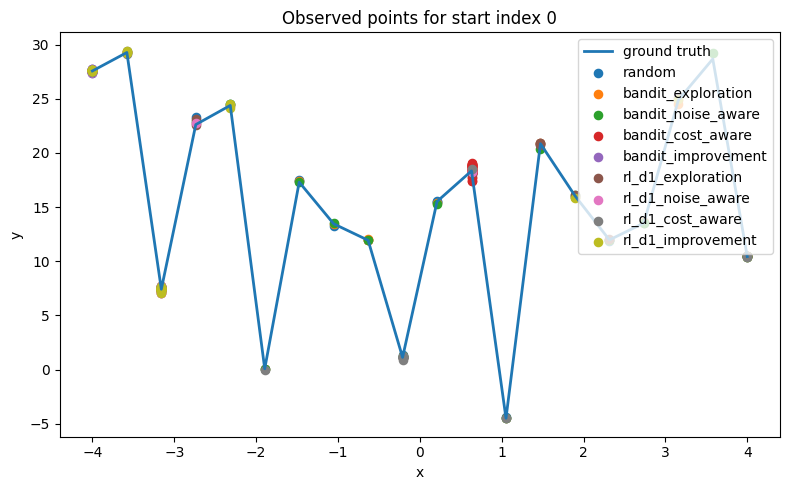

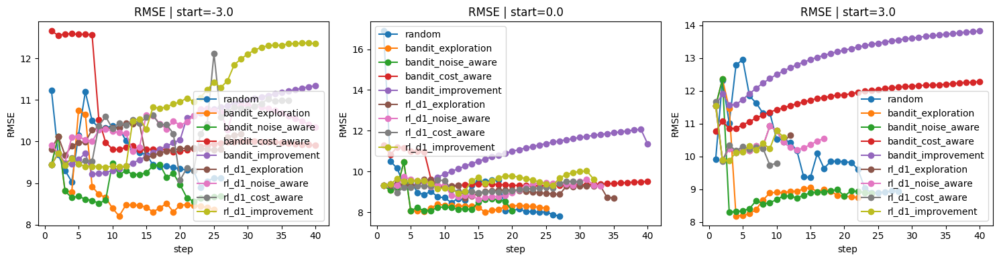

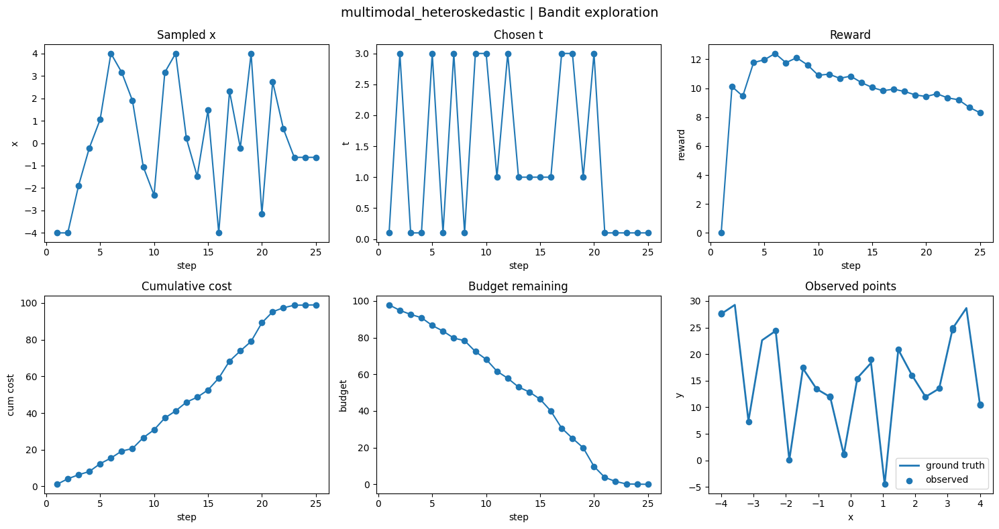

In [54]:
case_key = "multimodal_heteroskedastic"

problem = all_runs[case_key]["problem"]
results = all_runs[case_key]["results"]

plot_method_comparison(results, problem, start_points=start_points)
plot_summary_bars(results)
plot_final_observations(results, problem, start_index=0)
plot_rmse_comparison(results, start_points=start_points)
plot_single_trajectory(
    results["bandit_exploration"][0],
    problem,
    title=f"{case_key} | Bandit exploration"
)